Machine Learning Assignment 1 (Individual): Activity Recognition from Your Own Smartphone Sensor Data
**Héctor Cuenca Lifante · Atlantic Technological University ·**

This notebook extends **ML Assignment 1 — Starter notebook**, **Machine Learning · Atlantic Technological University · Dr Seán Mullery**. The original starter is included in `sources/` and must be credited in the paper and README. This edition translates and expands the learning notes.

**Minimal adaptation:** seven of the eleven non-empty original code cells are retained exactly, and four are adapted. Added sections implement the requirements left open by the starter. Each retained or adapted cell is labelled, and `starter_changes.csv` records its location and code hashes.

**Colour key for the comparison panels:** white means unchanged starter lines; amber means replacement lines; light green means inserted lines; pale red with a minus sign means removed starter lines. The panels are read-only displays next to ordinary executable Python. Comparison-display cells are separate from the analysis and can be collapsed. 

**Available study data:** 40 own recordings, with 10 SIT, 10 STAND, 10 WALK, 5 UP and 5 DOWN. The real class pool has not been supplied. Across-person code is implemented, but its scientific results and anonymous self-identification remain pending. Software fixtures used for checks are not participants and are not included as experiment results.


## 0 Setup and folder structure


`Path` represents a filesystem path; it does not read a file by itself. `DATA_DIR = Path("data")` is relative to the current working directory. `LABELS` is a set of permitted target labels. It validates names; it is not a list of model inputs. NumPy supplies numerical operations, pandas supplies tables, and Matplotlib supplies plots.

 `data/own` contains your unprefixed recordings and `data/pool` contains anonymous participant-prefixed recordings. 


In [1]:
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("data")
LABELS = {"SIT", "STAND", "WALK", "UP", "DOWN"}

### Added configuration and modelling imports

The next cell creates folders and defines values shared by later functions. `ART` points to `artifacts`, which will contain audit CSVs, figures, fitted models and configuration files. `SEED = 42` makes supported random choices repeatable. 

The cleaning rules are declared before held-out evaluation: remove 2 s at the common beginning, retain the common ending, reject windows crossing gaps above 0.10 s, require at least 80% of expected accelerometer readings and at least ten readings, and reject files with more than 1% non-finite sensor rows. These are practical rules to justify from development data.

Windows use elapsed time. The pipeline retains native rates and matches sensor timestamps instead of resampling to a uniform grid. Native-rate statistics can still be influenced by sampling frequency and irregular density, particularly extrema. The across-person experiment must assess that limitation.

`warnings.filterwarnings('error', category=ConvergenceWarning)` stops a run when an optimiser fails to converge, instead of silently accepting that fit. Resolve such issues using development data. New imports do not change the original setup cell.


In [2]:
import io
import re
import json
import hashlib
import platform
import warnings
from functools import lru_cache
from copy import deepcopy

import scipy
import sklearn
import joblib
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('error', category=ConvergenceWarning)
SEED = 42
ORDER = ['SIT', 'STAND', 'WALK', 'UP', 'DOWN']
OWN_DIR, POOL_DIR = DATA_DIR/'own', DATA_DIR/'pool'
ART = Path('artifacts')
for directory in (OWN_DIR, POOL_DIR, ART, ART/'figures', ART/'tables', ART/'models'):
    directory.mkdir(parents=True, exist_ok=True)
CLEANING = dict(trim_start_s=2.0, trim_end_s=0.0, max_gap_s=0.10,
                max_bad_fraction=0.01, min_window_coverage=0.80,
                min_samples=10)
VERSIONS = {'python':platform.python_version(), 'numpy':np.__version__,
            'pandas':pd.__version__, 'scipy':scipy.__version__,
            'scikit-learn':sklearn.__version__, 'joblib':joblib.__version__}
print(VERSIONS)
print('Cleaning rules:', CLEANING)


{'python': '3.14.6', 'numpy': '2.4.6', 'pandas': '3.0.3', 'scipy': '1.18.0', 'scikit-learn': '1.9.0', 'joblib': '1.5.3'}
Cleaning rules: {'trim_start_s': 2.0, 'trim_end_s': 0.0, 'max_gap_s': 0.1, 'max_bad_fraction': 0.01, 'min_window_coverage': 0.8, 'min_samples': 10}


## 1 Read a phyphox export and its metadata

**Adapted starter code cell 4.** The coloured comparison identifies the small reader checks and the one-line extension for participant codes containing underscores. The public function names and basic reading approach are retained.

**`read_sensor(zip_path, sensor)`** accepts the path to an individual export ZIP and either `Accelerometer` or `Gyroscope`. `zipfile.ZipFile` opens the archive; `namelist()` lists internal paths. The function finds a matching sensor filename in any subfolder and ignores `__MACOSX`. It requires exactly one match, because choosing arbitrarily between two copies would be ambiguous. `pd.read_csv` reads the CSV through the ZIP handle without extracting it. Four columns are required, then renamed `t, x, y, z`. The export order is assumed to be time followed by the three axes. Numeric conversion and timing checks happen later in `tidy_sensor`.

**`read_meta(zip_path, name)`** uses the same search strategy for `meta/time.csv` or `meta/device.csv`. Missing or multiple matching metadata files raise a descriptive `ValueError`. It returns the metadata table; it does not validate every field.

**`parse_name(zip_path)`** reads the recording identity from its name, not from the signal. It returns `recording`, `code`, `label` and integer `nn`, or `None` for an unrecognised name. Unprefixed `UP_03.zip` becomes code `me`. `rsplit('_', 2)` splits from the right, so `S07_1_STAND_02.zip` retains the participant code `S07_1`. This one-line change accommodates the naming pattern shown in your timestamp example. Labels remain required to match the expected uppercase values. Correct naming does not prove that the performed activity was correctly labelled.


In [3]:
#@title Coloured starter comparison — read only
from IPython.display import HTML, display
display(HTML('<div style="font-family:system-ui,sans-serif;border:1px solid #d1d5db;padding:12px;border-radius:6px;background:white;color:#111827"><p style="margin:0 0 8px;font-weight:700">Adapted original starter code cell 4 — line comparison</p><p style="margin:0 0 8px;font-size:13px">White: retained · Amber (~): replaced · Green (+): inserted · Red (−): removed original</p><pre style="font-family:DejaVu Sans Mono,Consolas,monospace;font-size:12px;line-height:1.35;margin:0;overflow-x:auto"><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;">  1   def read_sensor(zip_path, sensor=&quot;Accelerometer&quot;):</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;">  2       &quot;&quot;&quot;Read one sensor CSV from a phyphox zip. Returns columns t, x, y, z.&quot;&quot;&quot;</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;">  3       with zipfile.ZipFile(zip_path) as z:</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;">  4           matches = [n for n in z.namelist()</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;">  5                      if n.endswith(f&quot;{sensor}.csv&quot;) and &quot;__MACOSX&quot; not in n]</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;">  6 ~         if len(matches) != 1:</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;">  7 ~             raise ValueError(f&quot;Expected one {sensor}.csv in {zip_path}; found {len(matches)}&quot;)</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;">  8           with z.open(matches[0]) as f:</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;">  9               df = pd.read_csv(f)</span><span style="display:block;background-color:#dcfce7;color:#14532d;padding:1px 8px;white-space:pre;"> 10 +     if df.shape[1] != 4:</span><span style="display:block;background-color:#dcfce7;color:#14532d;padding:1px 8px;white-space:pre;"> 11 +         raise ValueError(f&quot;Expected time + 3 axes in {zip_path}: {df.shape[1]} columns&quot;)</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 12       df.columns = [&quot;t&quot;, &quot;x&quot;, &quot;y&quot;, &quot;z&quot;]   # time (s) and the three axes</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 13       return df</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 14   </span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 15   </span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 16   def read_meta(zip_path, name=&quot;time&quot;):</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 17       &quot;&quot;&quot;Read meta/time.csv or meta/device.csv from a phyphox zip.&quot;&quot;&quot;</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 18       with zipfile.ZipFile(zip_path) as z:</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 19           matches = [n for n in z.namelist()</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 20                      if n.endswith(f&quot;meta/{name}.csv&quot;) and &quot;__MACOSX&quot; not in n]</span><span style="display:block;background-color:#dcfce7;color:#14532d;padding:1px 8px;white-space:pre;"> 21 +         if len(matches) != 1:</span><span style="display:block;background-color:#dcfce7;color:#14532d;padding:1px 8px;white-space:pre;"> 22 +             raise ValueError(f&quot;Missing or ambiguous meta/{name}.csv in {zip_path}&quot;)</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 23           with z.open(matches[0]) as f:</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 24               return pd.read_csv(f)</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 25   </span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 26   </span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 27   def parse_name(zip_path):</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 28       &quot;&quot;&quot;Split UP_03.zip (your own) or S03_UP_03.zip (pooled) into its parts.&quot;&quot;&quot;</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 29 ~     parts = Path(zip_path).stem.rsplit(&quot;_&quot;, 2)</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 30       if len(parts) == 2:</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 31           parts = [&quot;me&quot;] + parts            # your own file: no code yet</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 32       if len(parts) != 3 or parts[1] not in LABELS or not parts[2].isdigit():</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 33           return None</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 34       code, label, nn = parts</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 35       return {&quot;recording&quot;: Path(zip_path).stem, &quot;code&quot;: code,</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 36               &quot;label&quot;: label, &quot;nn&quot;: int(nn)}</span></pre><p style="font-weight:600;margin:10px 0 4px">Removed or replaced starter lines</p><pre style="font-size:12px;line-height:1.35;margin:0;overflow-x:auto"><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;">  6 -         if not matches:</span><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;">  7 -             raise FileNotFoundError(f&quot;No {sensor}.csv in {zip_path}&quot;)</span><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;"> 25 -     parts = Path(zip_path).stem.split(&quot;_&quot;)</span></pre></div>'))


In [4]:
def read_sensor(zip_path, sensor="Accelerometer"):
    """Read one sensor CSV from a phyphox zip. Returns columns t, x, y, z."""
    with zipfile.ZipFile(zip_path) as z:
        matches = [n for n in z.namelist()
                   if n.endswith(f"{sensor}.csv") and "__MACOSX" not in n]
        if len(matches) != 1:
            raise ValueError(f"Expected one {sensor}.csv in {zip_path}; found {len(matches)}")
        with z.open(matches[0]) as f:
            df = pd.read_csv(f)
    if df.shape[1] != 4:
        raise ValueError(f"Expected time + 3 axes in {zip_path}: {df.shape[1]} columns")
    df.columns = ["t", "x", "y", "z"]   # time (s) and the three axes
    return df


def read_meta(zip_path, name="time"):
    """Read meta/time.csv or meta/device.csv from a phyphox zip."""
    with zipfile.ZipFile(zip_path) as z:
        matches = [n for n in z.namelist()
                   if n.endswith(f"meta/{name}.csv") and "__MACOSX" not in n]
        if len(matches) != 1:
            raise ValueError(f"Missing or ambiguous meta/{name}.csv in {zip_path}")
        with z.open(matches[0]) as f:
            return pd.read_csv(f)


def parse_name(zip_path):
    """Split UP_03.zip (your own) or S03_UP_03.zip (pooled) into its parts."""
    parts = Path(zip_path).stem.rsplit("_", 2)
    if len(parts) == 2:
        parts = ["me"] + parts            # your own file: no code yet
    if len(parts) != 3 or parts[1] not in LABELS or not parts[2].isdigit():
        return None
    code, label, nn = parts
    return {"recording": Path(zip_path).stem, "code": code,
            "label": label, "nn": int(nn)}


## 2 Import your raw recordings

In Visual Studio Code, set `UPLOAD_OWN_ARCHIVE = True`, run the next cell and select **Row_Data_Hector.zip**. Reset the flag to False after import. Alternatively, upload that archive through the Files panel; it is automatically imported if `data/own` is empty. When using the complete local package, the recordings are already in that folder.

**`import_archive(archive, destination)`** opens a containing archive, searches for appropriately named individual recording ZIPs and copies their bytes into the destination. The outer folder can be `Data/` or another name. It does not unpack or edit the contents of an individual phyphox export. Existing files with identical names and different bytes cause an explicit collision error rather than being overwritten. Ignored entries are reported for review.

**`upload_archives(destination)`** uses Visual Studio Code's upload interface. A selected individual recording is copied directly; a containing archive is passed to `import_archive`.

For the real pool, use `UPLOAD_POOL_ARCHIVE = True` or populate `data/pool`. Keep other participants out of `data/own`. The assertion at the end stops execution if there are no own ZIPs to process.


In [5]:
UPLOAD_OWN_ARCHIVE = False
UPLOAD_POOL_ARCHIVE = False

def import_archive(archive, destination):
    """Import named recording ZIPs, preserving each original export byte for byte."""
    archive = Path(archive)
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)
    copied, ignored = [], []
    with zipfile.ZipFile(archive) as outer:
        for item in outer.infolist():
            name = Path(item.filename).name
            if item.is_dir() or '__MACOSX' in item.filename:
                continue
            if not name.lower().endswith('.zip'):
                ignored.append(item.filename)
                continue
            if parse_name(Path(name)) is None:
                ignored.append(item.filename)
                continue
            target = destination/name
            payload = outer.read(item)
            if target.exists() and target.read_bytes() != payload:
                raise ValueError(f'File name collision: {target}. Review it before importing.')
            target.write_bytes(payload)
            copied.append(name)
    print(f'{archive.name}: {len(copied)} ZIPs imported; {len(ignored)} entries ignored.')
    if ignored:
        display(pd.DataFrame({'ignored_archive_entry':ignored}))
    if not copied:
        raise ValueError('The archive contained no ZIPs with recognised recording names.')

def upload_archives(destination):
    from google.colab import files as colab_files
    uploaded = colab_files.upload()
    for name in uploaded:
        if name.lower().endswith('.zip'):
            if parse_name(Path(name)) is not None:
                target = destination/Path(name).name
                if target.exists() and target.read_bytes() != uploaded[name]:
                    raise ValueError(f'File name collision: {target}')
                target.write_bytes(uploaded[name])
            else:
                import_archive(Path(name), destination)
        else:
            print('Ignored upload:', name)

if UPLOAD_OWN_ARCHIVE:
    upload_archives(OWN_DIR)
elif Path('Row_Data_Hector.zip').exists() and not list(OWN_DIR.glob('*.zip')):
    import_archive(Path('Row_Data_Hector.zip'), OWN_DIR)
if UPLOAD_POOL_ARCHIVE:
    upload_archives(POOL_DIR)
assert list(OWN_DIR.rglob('*.zip')), 'Upload Row_Data_Hector.zip or populate data/own first.'


## 3 Inventory, duplicate checks and a recording-level split

**`fingerprint(path)`** reads both sensor tables, converts their values to floating point, rounds to eight decimal places, and hashes sensor identity, array shape and numerical bytes with SHA-256. Internal ZIP folders, CSV header wording and metadata do not determine this fingerprint. This detects identical numerical sensor content even when an export has been repackaged. Rounding is a documented numerical matching convention, not proof that two independently collected similar activities are the same recording. A separate ZIP-byte hash records original-file integrity.

**`build_catalog(paths)`** returns one inventory row per file. It records name parsing, hashes, naming warnings, eligibility and a reason. Same-content/same-label duplicates are retained once per participant, in deterministic recording-number/path order. Conflicting labels for the same content exclude all conflicting files instead of guessing a label. Repeated recording identifiers with different sensor data are also rejected. A noncanonical name such as `STAND_2.zip` is warned about while the original file is preserved.

| Activity | Development recordings | Reserved test recordings |
|---|---|---|
| SIT, STAND, WALK | 01–07 in each class | 08–10 in each class |
| UP, DOWN | 01–03 in each class | 04–05 in each class |

The `.copy()` calls create separate catalogue tables. `set(...).isdisjoint(...)` asserts that development and test share neither recording IDs nor content fingerprints. Hashing all files is used for duplicate control; signal exploration and all setting choices use development only. Every window inherits its source recording's partition. Metadata identifiers never become predictors.


In [6]:
def fingerprint(path):
    digest = hashlib.sha256()
    for sensor in ('Accelerometer', 'Gyroscope'):
        values = read_sensor(path, sensor).apply(pd.to_numeric, errors='coerce')
        values = np.round(values.to_numpy(dtype=np.float64), 8).astype('<f8')
        digest.update(sensor.encode())
        digest.update(str(values.shape).encode())
        digest.update(values.tobytes())
    return digest.hexdigest()

def build_catalog(paths):
    records = []
    for path in sorted(map(Path, paths)):
        info = parse_name(path)
        row = dict(path=str(path), file=path.name, eligible=True, reason='', naming_warning='')
        if info is None:
            records.append(dict(row, eligible=False, reason='unrecognised filename'))
            continue
        row.update(info)
        canonical = f"{info['label']}_{info['nn']:02d}.zip"
        if info['code'] != 'me':
            canonical = info['code']+'_'+canonical
        if path.name != canonical:
            row['naming_warning'] = f'Protocol spelling: {canonical}; original preserved'
        try:
            row['signature'] = fingerprint(path)
            row['zip_sha256'] = hashlib.sha256(path.read_bytes()).hexdigest()
        except Exception as exc:
            row.update(eligible=False, reason=f'reading failed: {type(exc).__name__}: {exc}')
        records.append(row)
    cat = pd.DataFrame(records)
    if cat.empty:
        return cat
    valid = cat[cat.eligible & cat.signature.notna()] if 'signature' in cat else cat.iloc[0:0]
    for (_, signature), grp in valid.groupby(['code', 'signature']):
        if len(grp) < 2:
            continue
        if grp.label.nunique() > 1:
            cat.loc[grp.index, ['eligible','reason']] = [False, 'duplicate sensor content with conflicting labels']
        else:
            ordered = grp.sort_values(['nn','path'])
            cat.loc[ordered.index[1:], ['eligible','reason']] = [False, f"duplicate of {ordered.iloc[0]['file']}"]
    if 'recording' in cat:
        active = cat[cat.eligible]
        for recording, grp in active.groupby('recording'):
            if len(grp) > 1:
                cat.loc[grp.index, ['eligible','reason']] = [False, 'same recording identifier with different sensor data']
    return cat

own_catalog = build_catalog(OWN_DIR.rglob('*.zip'))
assert not own_catalog.empty
if own_catalog.loc[own_catalog.eligible, 'code'].ne('me').any():
    raise ValueError('data/own must contain only your unprefixed recording files.')
own_catalog['split'] = own_catalog.apply(
    lambda r: 'development' if r.get('nn', np.inf) <= (3 if r.get('label') in ['UP','DOWN'] else 7) else 'test', axis=1)
own_catalog.to_csv(ART/'tables/own_manifest.csv', index=False)
dev_catalog = own_catalog[own_catalog.eligible & own_catalog.split.eq('development')].copy()
test_catalog = own_catalog[own_catalog.eligible & own_catalog.split.eq('test')].copy()
assert set(dev_catalog.recording).isdisjoint(test_catalog.recording)
assert set(dev_catalog.signature).isdisjoint(test_catalog.signature)
display(pd.crosstab(own_catalog.label, own_catalog.split).reindex(ORDER))
display(own_catalog.loc[own_catalog.naming_warning.ne('') | ~own_catalog.eligible,
                        ['file','naming_warning','eligible','reason']])
print('Development:', len(dev_catalog), 'recordings; test:', len(test_catalog))


split,development,test
label,,
SIT,7,3
STAND,7,3
WALK,7,3
UP,3,2
DOWN,3,2


,file,naming_warning,eligible,reason
23,STAND_2.zip,Protocol spelling: STAND_02.zip; original pres...,True,
24,STAND_3.zip,Protocol spelling: STAND_03.zip; original pres...,True,


Development: 27 recordings; test: 13


## 4 Inspect a real development recording

**Adapted starter code cell 6.** File discovery uses the development catalogue and the example is explicitly `SIT_01.zip`, falling back to the first development file if needed. This makes the initial-transient discussion reproducible. `acc.head()` shows raw sensor rows; a sensor row is not yet a training example. Later, a complete time window becomes one example.

| Class | Physical expectation | What to investigate in development |
|---|---|---|
| SIT | Low motion, with gravity distributed according to phone inclination | Initial handling or posture transitions; orientation differences between takes |
| STAND | Low motion that can resemble SIT | Whether axis means contain useful posture information |
| WALK | Repeated changes associated with steps | Variability, range and rotational movement |
| UP | Repeated gait with different leg movement from level walking | Combinations of acceleration and angular-velocity features |
| DOWN | Repeated gait and potentially different impacts from UP | Overlap with UP/WALK and whether several features help |

These are hypotheses to check, not guaranteed class rules. In these development recordings WALK magnitude variability is larger than that of the stairs. UP is not defined by positive phone-axis acceleration, nor DOWN by negative acceleration. If the measured signals for SIT and STAND were indistinguishable, no classifier could reliably separate them using those signals.


In [7]:
#@title Coloured starter comparison — read only
from IPython.display import HTML, display
display(HTML('<div style="font-family:system-ui,sans-serif;border:1px solid #d1d5db;padding:12px;border-radius:6px;background:white;color:#111827"><p style="margin:0 0 8px;font-weight:700">Adapted original starter code cell 6 — line comparison</p><p style="margin:0 0 8px;font-size:13px">White: retained · Amber (~): replaced · Green (+): inserted · Red (−): removed original</p><pre style="font-family:DejaVu Sans Mono,Consolas,monospace;font-size:12px;line-height:1.35;margin:0;overflow-x:auto"><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;">  1 ~ files = sorted(Path(p) for p in dev_catalog.path)</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;">  2 ~ print(f&quot;{len(files)} development zip files found&quot;)</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;">  3 ~ example = next((f for f in files if f.name == &#x27;SIT_01.zip&#x27;), files[0])</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;">  4   acc = read_sensor(example, &quot;Accelerometer&quot;)</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;">  5   print(example.name, parse_name(example))</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;">  6   acc.head()</span></pre><p style="font-weight:600;margin:10px 0 4px">Removed or replaced starter lines</p><pre style="font-size:12px;line-height:1.35;margin:0;overflow-x:auto"><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;">  1 - files = sorted(DATA_DIR.glob(&quot;*.zip&quot;))</span><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;">  2 - print(f&quot;{len(files)} zip files found&quot;)</span><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;">  3 - </span><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;">  4 - example = next(f for f in files if parse_name(f) is not None)   # first correctly named file</span></pre></div>'))


In [8]:
files = sorted(Path(p) for p in dev_catalog.path)
print(f"{len(files)} development zip files found")
example = next((f for f in files if f.name == 'SIT_01.zip'), files[0])
acc = read_sensor(example, "Accelerometer")
print(example.name, parse_name(example))
acc.head()


27 development zip files found
SIT_01.zip {'recording': 'SIT_01', 'code': 'me', 'label': 'SIT', 'nn': 1}


,t,x,y,z
0,0.007438,9.849746,1.142034,0.541090
1,0.009530,9.959879,1.039083,0.500388
2,0.011553,9.935937,0.826000,0.672771
3,0.013610,9.751583,0.670376,1.182736
4,0.015822,9.648633,0.586579,1.745373


### Inspect the start and pause log

**Original starter code cell 8, unchanged.** `read_meta(example, "time")` shows acquisition events. One START followed by a final PAUSE is the normal completed-run pattern in your exports. More than one START indicates a resumed recording. Sensor timestamps can appear continuous even when the acquisition was paused, so this log matters independently of the sensor plots.


In [9]:
read_meta(example, "time")

,event,experiment time,system time,system time text
0,START,0.000000,1.792186e+09,2026-10-16 23:34:37.752 UTC+02:00
1,PAUSE,30.005178,1.792187e+09,2026-10-16 23:35:07.758 UTC+02:00


### Plot the raw accelerometer

**Original starter code cell 10, unchanged.** The magnitude is added as the square root of the sum of squared axes. Each line is plotted against its own recorded time. At rest, acceleration magnitude is about 9.81 m/s² because gravity is included. The gyroscope, considered later, measures angular velocity in rad/s, not an orientation angle. Preserve axes as well as magnitude: equal magnitudes can correspond to different inclinations.


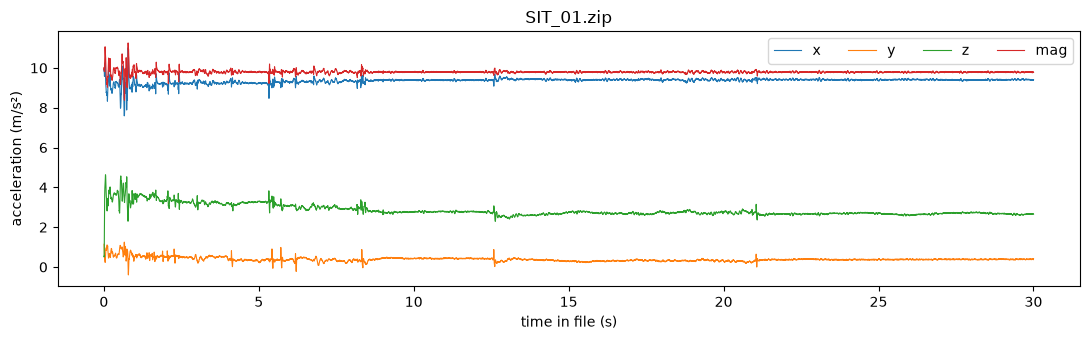

In [10]:
acc["mag"] = np.sqrt(acc.x**2 + acc.y**2 + acc.z**2)   # overall size of the movement

fig, ax = plt.subplots(figsize=(11, 3.5))
for col in ["x", "y", "z", "mag"]:
    ax.plot(acc.t, acc[col], label=col, lw=0.8)
ax.set_xlabel("time in file (s)")
ax.set_ylabel("acceleration (m/s²)")
ax.set_title(example.name)
ax.legend(loc="upper right", ncol=4)
plt.tight_layout()
plt.show()

## 5 General cleaning and timestamp alignment

This added cell contains two key functions. First, each sensor is cleaned separately using `tidy_sensor()`. Then, `clean_recording()` checks the metadata, trims the interval, and pairs the readings.

**`tidy_sensor(frame, sensor)`** returns a numeric sensor table and quality counts. `pd.to_numeric(errors='coerce')` turns unparseable values into NaN. `np.isfinite(...).all(axis=1)` retains a row only if its time and all three axes are finite. More than 1% invalid rows reject the file; otherwise those rows are removed. Negative successive time differences reject a backwards time sequence. Repeated timestamps are collapsed by keeping the first occurrence. At least two usable readings and a positive median interval are required. These checks occur before nearest-time matching, which requires ordered timestamps.

**`clean_recording(path)`** returns `(aligned, audit)`:

1. Read `meta/time.csv`, require `event` and `experiment time`, normalise event strings with `astype(str).str.upper().str.strip()`, then count START and PAUSE values. Reject unless there is exactly one START, at most one PAUSE, and START is the first event. This is a minimum check: it does not validate numeric metadata times, require a final PAUSE, or reject every unknown event name. Missing/ambiguous metadata and file-reading errors are caught by the caller.
2. Clean each sensor using `tidy_sensor`. Estimate typical sample intervals from the median positive time difference.
3. Find the shared sensor interval using the later start and earlier end. Remove 2 s from its beginning and the configured amount from its end. Reject when less than 3 s remain.
4. Calculate both sensor magnitudes. Rename gyro fields to `gyro_t, gx, gy, gz, gmag`, keeping gyro time for verification.
5. `pd.merge_asof(..., direction='nearest')` assigns the nearest gyro reading to each accelerometer timestamp. Its tolerance is `min(0.05, max(0.01, 2.5*median_gyro_interval))` seconds. Different row numbers can therefore be paired. This assumes a shared elapsed-time reference; it does not estimate an unknown physical clock offset or clock drift.
6. Keep the shared trimmed interval, count unmatched readings, and drop incomplete pairs. Preserve `abs(t - gyro_t)` as the residual timestamp difference. These are approximate temporal pairs, not measurements made exactly simultaneously.
7. Return quality evidence: rates, largest gaps, invalid-row/duplicate counts, unmatched counts, and alignment percentiles. Large internal gaps are screened at the window stage rather than being filled with fabricated samples.

**`@lru_cache(maxsize=512)`** caches up to 512 successful calls with distinct arguments in RAM, evicting the least recently used entry when full. It avoids repeatedly opening and cleaning the same file during window-setting comparisons. Cached values depend on the path argument, not changes made later to the file or global `CLEANING`. After editing either, run `clean_recording.cache_clear()` or restart/redefine the function. If you remove the decorator, retain the function and remove any `.cache_clear()` call; calculations are recomputed on each call.

The `try/except` loop builds `dev_qc`. A rejected file receives `usable=False` and an explicit reason. Actual feature construction later catches the same exception and leaves that file out of the feature table. Rejection does not delete an original ZIP. The displayed columns are a subset of the full audit CSV.


In [11]:
def tidy_sensor(frame, sensor):
    frame = frame.apply(pd.to_numeric, errors='coerce')
    finite = np.isfinite(frame.to_numpy()).all(axis=1)
    bad = int((~finite).sum())
    if not len(frame) or bad/len(frame) > CLEANING['max_bad_fraction']:
        raise ValueError(f'{sensor}: too many non-finite or nonnumeric rows')
    frame = frame.loc[finite].copy()
    if (frame.t.diff().dropna() < 0).any():
        raise ValueError(f'{sensor}: timestamps go backwards')
    duplicates = int(frame.t.duplicated().sum())
    frame = frame.drop_duplicates('t', keep='first').reset_index(drop=True)
    if len(frame) < 2 or frame.t.diff().median() <= 0:
        raise ValueError(f'{sensor}: insufficient usable timing')
    return frame, {'bad_rows':bad, 'duplicate_timestamps':duplicates}

@lru_cache(maxsize=512)
def clean_recording(path):
    path = Path(path)
    meta = read_meta(path, 'time')
    if 'event' not in meta or 'experiment time' not in meta:
        raise ValueError('meta/time.csv lacks event or experiment time')
    events = meta.event.astype(str).str.upper().str.strip()
    starts = int(events.eq('START').sum())
    pauses = int(events.eq('PAUSE').sum())
    if starts != 1 or pauses > 1 or not events.iloc[0] == 'START':
        raise ValueError(f'paused/restarted or invalid metadata: START={starts}, PAUSE={pauses}')
    acc, aq = tidy_sensor(read_sensor(path, 'Accelerometer'), 'accelerometer')
    gyro, gq = tidy_sensor(read_sensor(path, 'Gyroscope'), 'gyroscope')
    dt_a, dt_g = float(acc.t.diff().median()), float(gyro.t.diff().median())
    tolerance = min(0.05, max(0.01, 2.5*dt_g))
    first = max(float(acc.t.iloc[0]), float(gyro.t.iloc[0]))
    last = min(float(acc.t.iloc[-1]), float(gyro.t.iloc[-1]))
    left, right = first+CLEANING['trim_start_s'], last-CLEANING['trim_end_s']
    if right-left < 3.0:
        raise ValueError('less than 3 s remain after common-interval trimming')
    acc['mag'] = np.sqrt(acc.x**2 + acc.y**2 + acc.z**2)
    gyro['gmag'] = np.sqrt(gyro.x**2 + gyro.y**2 + gyro.z**2)
    gyro = gyro.rename(columns={'t':'gyro_t','x':'gx','y':'gy','z':'gz'})
    aligned = pd.merge_asof(acc, gyro, left_on='t', right_on='gyro_t',
                            direction='nearest', tolerance=tolerance)
    in_interval = aligned.t.between(left, right)
    unmatched = int(aligned.loc[in_interval, 'gyro_t'].isna().sum())
    aligned = aligned.loc[in_interval].dropna().reset_index(drop=True)
    if len(aligned) < CLEANING['min_samples'] or aligned.t.iloc[-1]-aligned.t.iloc[0] < 3:
        raise ValueError('insufficient aligned data')
    # Nearest matching has a tolerance: it cannot pair readings across a long dropout.
    aligned['alignment_error_s'] = (aligned.t-aligned.gyro_t).abs()
    audit = dict(file=path.name, start_count=starts, pause_count=pauses,
                 raw_duration_s=last-first, kept_duration_s=aligned.t.iloc[-1]-aligned.t.iloc[0],
                 acc_hz=1/dt_a, gyr_hz=1/dt_g, acc_max_gap_s=float(acc.t.diff().max()),
                 gyr_max_gap_s=float(gyro.gyro_t.diff().max()),
                 dropped_bad_rows_acc=aq['bad_rows'], dropped_bad_rows_gyr=gq['bad_rows'],
                 duplicate_times_acc=aq['duplicate_timestamps'], duplicate_times_gyr=gq['duplicate_timestamps'],
                 unmatched_samples=unmatched, align_tolerance_s=tolerance,
                 alignment_p95_s=float(aligned.alignment_error_s.quantile(.95)),
                 alignment_max_s=float(aligned.alignment_error_s.max()),
                 expected_acc_hz=1/dt_a)
    return aligned, audit

dev_qc = []
for path in dev_catalog.path:
    try:
        _, audit = clean_recording(path)
        dev_qc.append(dict(audit, usable=True, reason=''))
    except Exception as exc:
        dev_qc.append(dict(file=Path(path).name, usable=False, reason=str(exc)))
dev_qc = pd.DataFrame(dev_qc)
dev_qc.to_csv(ART/'tables/development_cleaning_audit.csv', index=False)
display(dev_qc[['file','usable','raw_duration_s','acc_hz','gyr_hz','start_count','alignment_p95_s','reason']].round(5))


,file,usable,raw_duration_s,acc_hz,gyr_hz,start_count,alignment_p95_s,reason
0,DOWN_01.zip,True,29.99920,499.02192,499.11706,1,0.00022,
1,DOWN_02.zip,True,29.99763,499.79009,499.95250,1,0.00022,
2,DOWN_03.zip,True,29.99309,499.80757,499.25112,1,0.00022,
3,SIT_01.zip,True,29.99465,486.31746,490.99756,1,0.00022,
4,SIT_02.zip,True,29.99852,494.26895,493.83692,1,0.00022,
5,SIT_03.zip,True,29.99907,486.36240,486.40451,1,0.00022,
6,SIT_04.zip,True,29.99539,494.28703,493.97596,1,0.00022,
7,SIT_05.zip,True,30.00564,494.10776,491.21463,1,0.00022,
8,SIT_06.zip,True,30.00469,494.31537,495.55880,1,0.00022,
9,SIT_07.zip,True,29.99868,496.13511,495.11568,1,0.00022,


## 6 Evidence before and after cleaning

The first figure uses a 5 × 2 grid: one development recording per class, with acceleration magnitude on the left and angular-speed magnitude on the right. The first recording number in each class is chosen systematically rather than selecting whichever trace looks best. Grey shows raw data, blue shows retained data, and orange marks the removed beginning. Original time coordinates are preserved. Vertical scales are not shared, so compare numerical axis values rather than apparent peak heights across panels.

For each file, `read_sensor` obtains the untouched streams and `clean_recording` supplies the processed table. The small inner loop reuses the same plotting code for both sensors; renaming the selected magnitude to `value` gives it a common column name. Acceleration after trimming generally overlaps the original values. Retained gyro values are plotted on the matched accelerometer reference times. This figure mainly evidences the initial trim; it is not a smoothing operation.

In SIT_01, the removed beginning has acceleration-magnitude SD about 0.336 m/s² versus 0.045 m/s² in the retained part. Mean angular-speed magnitude is about 0.107 versus 0.018 rad/s. These observations support an initial transition; the signal alone does not prove that inserting the phone into a pocket caused it. A uniform 2 s rule is a practical development-based choice and also removes valid beginning data from some files. 

The second figure uses the earlier `example`, SIT_01. Its left panel plots `t.diff()` for each sensor. `diff` is the interval between successive readings, `dropna` removes the first undefined interval, and multiplication by 1,000 converts seconds to milliseconds. About 2 ms corresponds to roughly 500 Hz; the distribution's width shows irregular timing. `bins=50` specifies histogram groups, not a sensor frequency. This is a diagnosis of native timing, not an after-resampling plot.

The right panel compares absolute timestamp differences from row-index pairing with nearest-time pairing. `n = min(...)` only makes the deliberately row-based comparison arrays the same length. The actual pipeline uses `merge_asof`, not this truncation. Raw index errors include the full file, whereas matched errors use the trimmed interval, and the histogram bins are separately calculated. Bar heights alone cannot establish improved alignment.

For SIT_01, row-index and nearest-time pairing already give essentially the same residuals: median about 0.170 ms and maximum about 0.233 ms. The raw and retained counts are 14,737 and 13,753, mainly because of the initial trim. A comparison restricted to the same retained time interval is shown in the following diagnostic cell. Report this lack of change honestly. The method becomes important when row indices represent different moments, as in the 8.73 ms example you supplied.

The previous audit checks all development files, beyond these five examples. Across the saved own-data audits, no restart, invalid row, duplicated timestamp, unmatched retained sample, or gap above 100 ms was found; the largest observed raw gap was about 4.43 ms. Window rejections are counted later. State what was checked and found; evidence does not require inventing a defect or a repair.


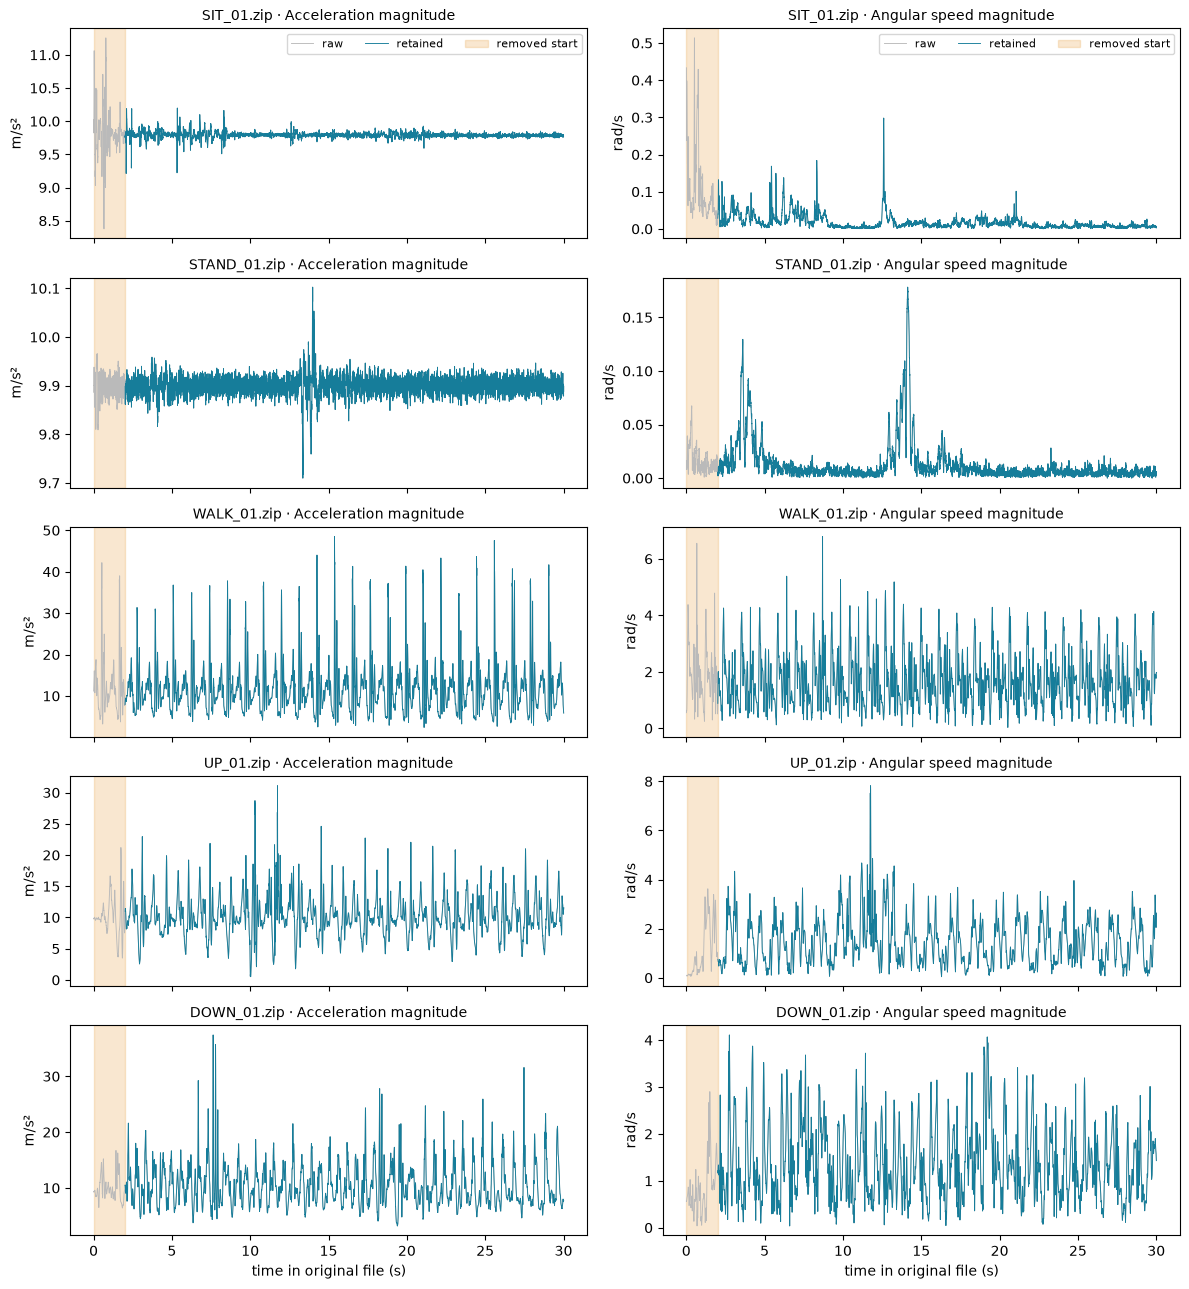

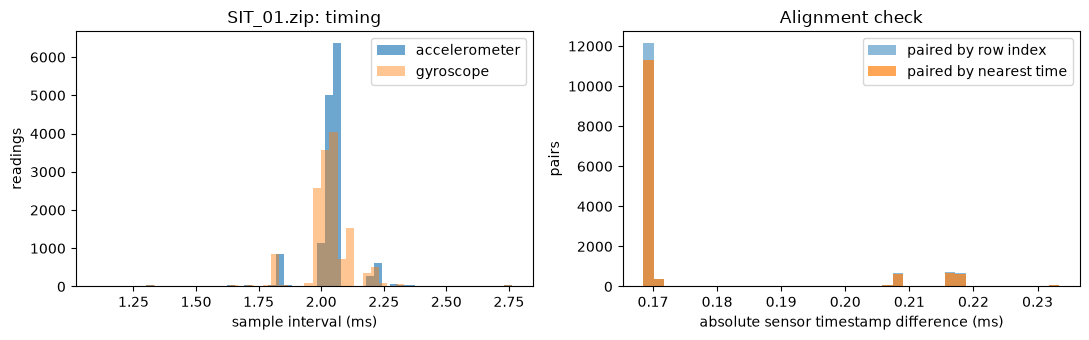

In [12]:
fig, axes = plt.subplots(5, 2, figsize=(12, 13), sharex=True)
for row, label in enumerate(ORDER):
    subset = dev_catalog[dev_catalog.label.eq(label)].sort_values('nn')
    path = Path(subset.iloc[0].path)
    raw_a = read_sensor(path, 'Accelerometer')
    raw_g = read_sensor(path, 'Gyroscope')
    clean, audit = clean_recording(str(path))
    for col, raw, cleaned, units, sensor in [
        (0, raw_a, clean[['t','mag']].rename(columns={'mag':'value'}), 'm/s²', 'Acceleration magnitude'),
        (1, raw_g, clean[['t','gmag']].rename(columns={'gmag':'value'}), 'rad/s', 'Angular speed magnitude')]:
        raw_mag = np.sqrt((raw[['x','y','z']]**2).sum(axis=1))
        ax = axes[row, col]
        ax.plot(raw.t, raw_mag, color='#bababa', lw=.65, label='raw')
        ax.plot(cleaned.t, cleaned.value, color='#167d9a', lw=.65, label='retained')
        ax.axvspan(raw.t.min(), clean.t.min(), color='#e8a046', alpha=.25, label='removed start')
        ax.set_title(f'{path.name} · {sensor}', fontsize=10)
        ax.set_ylabel(units)
        if row == 0:
            ax.legend(fontsize=8, ncol=3)
for ax in axes[-1]:
    ax.set_xlabel('time in original file (s)')
fig.tight_layout()
fig.savefig(ART/'figures/01_cleaning_before_after.png', dpi=160)
plt.show()

raw_a = read_sensor(example, 'Accelerometer')
raw_g = read_sensor(example, 'Gyroscope')
matched, _ = clean_recording(str(example))
n = min(len(raw_a), len(raw_g))
index_pair_error = np.abs(raw_a.t.to_numpy()[:n] - raw_g.t.to_numpy()[:n])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(raw_a.t.diff().dropna()*1000, bins=50, alpha=.65, label='accelerometer')
ax[0].hist(raw_g.t.diff().dropna()*1000, bins=50, alpha=.45, label='gyroscope')
ax[0].set(xlabel='sample interval (ms)', ylabel='readings', title=f'{example.name}: timing')
ax[0].legend()
ax[1].hist(index_pair_error*1000, bins=40, alpha=.5, label='paired by row index')
ax[1].hist(matched.alignment_error_s*1000, bins=40, alpha=.7, label='paired by nearest time')
ax[1].set(xlabel='absolute sensor timestamp difference (ms)', ylabel='pairs', title='Alignment check')
ax[1].legend()
fig.tight_layout()
fig.savefig(ART/'figures/02_timing_and_alignment.png', dpi=160)
plt.show()


### Additional timing check using the same retained interval

The comparison below restricts the row-index baseline to the same accelerometer interval as the cleaned pairs. This makes counts and quantiles comparable and avoids interpreting the initial-trim sample-count reduction as an alignment improvement. It does not change any cleaned signal or model input. For SIT_01 the two methods produce the same residuals on this interval. A different recording may show a genuine improvement.


In [13]:
same_interval = raw_a.t.iloc[:n].between(matched.t.min(), matched.t.max()).to_numpy()
index_error_same_interval = index_pair_error[same_interval]
timing_comparison = pd.DataFrame([
    {'method':'row index, retained interval', 'pairs':len(index_error_same_interval),
     'median_ms':np.median(index_error_same_interval)*1000,
     'p95_ms':np.quantile(index_error_same_interval,.95)*1000,
     'max_ms':np.max(index_error_same_interval)*1000},
    {'method':'nearest time, retained interval', 'pairs':len(matched),
     'median_ms':matched.alignment_error_s.median()*1000,
     'p95_ms':matched.alignment_error_s.quantile(.95)*1000,
     'max_ms':matched.alignment_error_s.max()*1000}
])
timing_comparison.to_csv(ART/'tables/timing_comparison_same_interval.csv',index=False)
display(timing_comparison.round(6))


,method,pairs,median_ms,p95_ms,max_ms
0,"row index, retained interval",13753,0.16954,0.21716,0.23338
1,"nearest time, retained interval",13753,0.16954,0.21716,0.23338


## 7 Understand the starter window generator

**Original starter code cell 12, unchanged.** `make_windows(df, length, overlap)` is a generator: each `yield` returns `(start, end, rows)` without building every window at once.

The step is `length * (1 - overlap)`. A 2 s window with 0.5 overlap advances by 1 s; with zero overlap it advances by 2 s. The Boolean mask selects `start <= t < end`, so a boundary reading belongs to the next window when there is no overlap. The loop yields full windows only; a short remaining tail is left unused. Windows are specified in seconds, not row counts, allowing different recording rates. The quality wrapper later checks coverage and large gaps.

The demonstration here deliberately uses the original raw `acc` table so the starter's mechanics remain unchanged. Training features later come from cleaned/aligned data. `windows[10]` selects the eleventh window because Python indexing starts at zero. Neighbouring/overlapping windows are correlated and must stay with the same recording in a data split.


In [14]:
def make_windows(df, length=2.0, overlap=0.5):
    """Yield (start, end, rows) for each full window in df, using the t column."""
    step = length * (1 - overlap)
    start = df.t.iloc[0]
    last = df.t.iloc[-1]
    while start + length <= last:
        end = start + length
        rows = df[(df.t >= start) & (df.t < end)]
        yield start, end, rows
        start += step


windows = list(make_windows(acc, length=2.5, overlap=0.5))
print(f"{len(windows)} windows from {example.name}")
start, end, rows = windows[10]
print(f"window 10 runs from {start:.2f} s to {end:.2f} s and holds {len(rows)} readings")

22 windows from SIT_01.zip
window 10 runs from 12.51 s to 15.01 s and holds 1228 readings


### Look inside one window

**Original starter code cell 14, unchanged.** Subtracting `start` puts the horizontal axis at zero at the beginning of this displayed window. It changes the plot's time origin, not the sensor values. The three lines are individual acceleration axes. Short windows respond sooner but may contain too little of a step cycle; longer windows describe more movement but add delay and can mix transitions. The later development comparison chooses between 2 and 3 s.


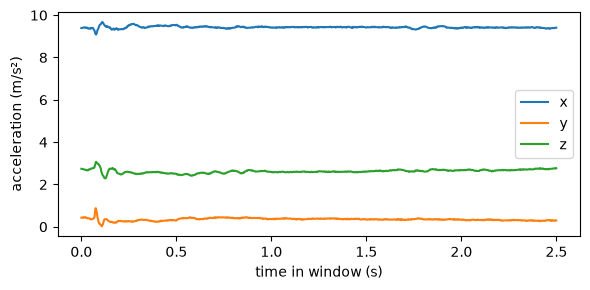

In [15]:
fig, ax = plt.subplots(figsize=(6, 3))
for col in ["x", "y", "z"]:
    ax.plot(rows.t - start, rows[col], label=col)
ax.set_xlabel("time in window (s)")
ax.set_ylabel("acceleration (m/s²)")
ax.legend()
plt.tight_layout()
plt.show()

## 8 Turn a window into summary statistics

**Original starter code cell 16, unchanged.** `window_stats(rows, columns, prefix)` returns a dictionary, which is a set of named feature/value pairs.

For every selected column, it calculates the mean, sample standard deviation, minimum, maximum and range. Pandas `std()` uses `ddof=1`, so at least two readings are needed mathematically; the pipeline sets a stronger quality minimum. Mean axis values can retain gravity/inclination, SD describes variation, and extrema/range describe amplitude. Range equals maximum minus minimum, so some features are redundant; regularisation and the representation comparison help assess the resulting model, without claiming each statistic contributes independently.

An f-string such as `f"{prefix}_{col}_mean"` gives a stable column name: prefix `acc` and column `y` produce `acc_y_mean`. The prefix prevents acceleration and gyro features from sharing names. Four signals per sensor × five statistics × two sensors = 40 features. One dictionary becomes one window row in a DataFrame; it is not one raw sample.


In [16]:
def window_stats(rows, columns, prefix):
    """Summary statistics of each column in one window, as a dict."""
    out = {}
    for col in columns:
        v = rows[col]
        out[f"{prefix}_{col}_mean"] = v.mean()
        out[f"{prefix}_{col}_sd"] = v.std()
        out[f"{prefix}_{col}_min"] = v.min()
        out[f"{prefix}_{col}_max"] = v.max()
        out[f"{prefix}_{col}_range"] = v.max() - v.min()
    return out


window_stats(rows, ["x", "y", "z", "mag"], prefix="acc")

{'acc_x_mean': np.float64(9.427791262313518),
 'acc_x_sd': np.float64(0.04904165991234396),
 'acc_x_min': np.float64(9.083600998),
 'acc_x_max': np.float64(9.679757118),
 'acc_x_range': np.float64(0.5961561199999998),
 'acc_y_mean': np.float64(0.3463891237250489),
 'acc_y_sd': np.float64(0.06382351851599696),
 'acc_y_min': np.float64(0.02154781483),
 'acc_y_max': np.float64(0.8762778044),
 'acc_y_range': np.float64(0.85472998957),
 'acc_z_mean': np.float64(2.6207481832516284),
 'acc_z_sd': np.float64(0.08509956761846814),
 'acc_z_min': np.float64(2.288856745),
 'acc_z_max': np.float64(3.071760893),
 'acc_z_range': np.float64(0.7829041480000001),
 'acc_mag_mean': np.float64(9.79202034483863),
 'acc_mag_sd': np.float64(0.04003387977087583),
 'acc_mag_min': np.float64(9.626733527465708),
 'acc_mag_max': np.float64(9.992582427579752),
 'acc_mag_range': np.float64(0.3658489001140435)}

## 9 Extract features from one cleaned recording

**Adapted starter code cell 18.** The window loop and `window_stats` are retained, while cleaning, gyro statistics and window-quality checks are added.

**Inputs:** a recording ZIP, window length in seconds, overlap fraction, and an inference-only `allow_unlabelled` flag. Invalid window arguments raise errors. A missing protocol-style filename is accepted only for explicitly unlabelled inference, where the placeholder label `UNKNOWN` is never used to train a model.

**Processing:** call `clean_recording`, then loop over full windows from its aligned table. `edge_times = np.r_[start, rows.t, end]` includes both window boundaries when checking gaps; this prevents accepting a window whose readings cover only its centre. Require at least `max(10, 0.8 * length * estimated_accelerometer_rate)` readings and no interval above 0.10 s. At 500 Hz a 3 s window expects about 1,500 rows and requires about 1,200. Ten is an absolute floor; the relative coverage requirement is normally stronger in these recordings. Counts refer to aligned rows, not independent measurements of every sensor.

For each accepted window, preserve identifiers separately and add acceleration statistics. Select gyro columns and temporarily rename them to `x,y,z,mag` so the unchanged `window_stats` function can be reused with prefix `gyr`. Invalid windows increment `skipped` and do not produce feature rows. Other valid windows remain usable.

**Output:** a feature DataFrame with one row per accepted window. `result.attrs['audit']` attaches quality information to this intermediate table; it is explicitly extracted into audit CSVs by the caller rather than relying on CSV to preserve DataFrame attributes. The original ZIP is never edited.


In [17]:
#@title Coloured starter comparison — read only
from IPython.display import HTML, display
display(HTML('<div style="font-family:system-ui,sans-serif;border:1px solid #d1d5db;padding:12px;border-radius:6px;background:white;color:#111827"><p style="margin:0 0 8px;font-weight:700">Adapted original starter code cell 18 — line comparison</p><p style="margin:0 0 8px;font-size:13px">White: retained · Amber (~): replaced · Green (+): inserted · Red (−): removed original</p><pre style="font-family:DejaVu Sans Mono,Consolas,monospace;font-size:12px;line-height:1.35;margin:0;overflow-x:auto"><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;">  1 ~ def features_for_recording(zip_path, length=2.0, overlap=0.5, allow_unlabelled=False):</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;">  2 ~     if length &lt;= 0 or not 0 &lt;= overlap &lt; 1:</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;">  3 ~         raise ValueError(&#x27;length must be positive; overlap must be in [0, 1)&#x27;)</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;">  4       info = parse_name(zip_path)</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;">  5 ~     if info is None:</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;">  6 ~         if not allow_unlabelled:</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;">  7 ~             raise ValueError(&#x27;Unrecognised recording name&#x27;)</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;">  8 ~         info = dict(recording=Path(zip_path).stem, code=&#x27;unseen&#x27;, label=&#x27;UNKNOWN&#x27;, nn=0)</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;">  9 ~     aligned, audit = clean_recording(str(zip_path))</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 10 ~     rows_out, skipped = [], 0</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 11 ~     for i, (start, end, rows) in enumerate(make_windows(aligned, length, overlap)):</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 12 ~         edge_times = np.r_[start, rows.t.to_numpy(), end]</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 13 ~         enough = len(rows) &gt;= max(CLEANING[&#x27;min_samples&#x27;],</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 14 ~                                  CLEANING[&#x27;min_window_coverage&#x27;]*length*audit[&#x27;expected_acc_hz&#x27;])</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 15 ~         if not enough or np.diff(edge_times).max() &gt; CLEANING[&#x27;max_gap_s&#x27;]:</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 16 ~             skipped += 1</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 17 ~             continue</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 18 ~         row = {**info, &#x27;window&#x27;:i, &#x27;start&#x27;:start, &#x27;end&#x27;:end}</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 19 ~         row.update(window_stats(rows, [&#x27;x&#x27;,&#x27;y&#x27;,&#x27;z&#x27;,&#x27;mag&#x27;], prefix=&#x27;acc&#x27;))</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 20 ~         gyro_rows = rows[[&#x27;gx&#x27;,&#x27;gy&#x27;,&#x27;gz&#x27;,&#x27;gmag&#x27;]].rename(</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 21 ~             columns={&#x27;gx&#x27;:&#x27;x&#x27;,&#x27;gy&#x27;:&#x27;y&#x27;,&#x27;gz&#x27;:&#x27;z&#x27;,&#x27;gmag&#x27;:&#x27;mag&#x27;})</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 22 ~         row.update(window_stats(gyro_rows, [&#x27;x&#x27;,&#x27;y&#x27;,&#x27;z&#x27;,&#x27;mag&#x27;], prefix=&#x27;gyr&#x27;))</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 23           rows_out.append(row)</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 24 ~     result = pd.DataFrame(rows_out)</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 25 ~     result.attrs[&#x27;audit&#x27;] = dict(audit, kept_windows=len(result), skipped_windows=skipped)</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 26 ~     return result</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 27   </span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 28   table = features_for_recording(example)</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 29   table.head()</span></pre><p style="font-weight:600;margin:10px 0 4px">Removed or replaced starter lines</p><pre style="font-size:12px;line-height:1.35;margin:0;overflow-x:auto"><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;">  1 - def features_for_recording(zip_path, length=2.0, overlap=0.5):</span><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;">  3 -     acc = read_sensor(zip_path, &quot;Accelerometer&quot;)</span><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;">  4 -     acc[&quot;mag&quot;] = np.sqrt(acc.x**2 + acc.y**2 + acc.z**2)</span><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;">  5 -     rows_out = []</span><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;">  6 -     for i, (start, end, rows) in enumerate(make_windows(acc, length, overlap)):</span><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;">  7 -         row = {**info, &quot;window&quot;: i, &quot;start&quot;: start, &quot;end&quot;: end}</span><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;">  8 -         row.update(window_stats(rows, [&quot;x&quot;, &quot;y&quot;, &quot;z&quot;, &quot;mag&quot;], prefix=&quot;acc&quot;))</span><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;"> 10 -     return pd.DataFrame(rows_out)</span><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;"> 11 - </span></pre></div>'))


In [18]:
def features_for_recording(zip_path, length=2.0, overlap=0.5, allow_unlabelled=False):
    if length <= 0 or not 0 <= overlap < 1:
        raise ValueError('length must be positive; overlap must be in [0, 1)')
    info = parse_name(zip_path)
    if info is None:
        if not allow_unlabelled:
            raise ValueError('Unrecognised recording name')
        info = dict(recording=Path(zip_path).stem, code='unseen', label='UNKNOWN', nn=0)
    aligned, audit = clean_recording(str(zip_path))
    rows_out, skipped = [], 0
    for i, (start, end, rows) in enumerate(make_windows(aligned, length, overlap)):
        edge_times = np.r_[start, rows.t.to_numpy(), end]
        enough = len(rows) >= max(CLEANING['min_samples'],
                                 CLEANING['min_window_coverage']*length*audit['expected_acc_hz'])
        if not enough or np.diff(edge_times).max() > CLEANING['max_gap_s']:
            skipped += 1
            continue
        row = {**info, 'window':i, 'start':start, 'end':end}
        row.update(window_stats(rows, ['x','y','z','mag'], prefix='acc'))
        gyro_rows = rows[['gx','gy','gz','gmag']].rename(
            columns={'gx':'x','gy':'y','gz':'z','gmag':'mag'})
        row.update(window_stats(gyro_rows, ['x','y','z','mag'], prefix='gyr'))
        rows_out.append(row)
    result = pd.DataFrame(rows_out)
    result.attrs['audit'] = dict(audit, kept_windows=len(result), skipped_windows=skipped)
    return result

table = features_for_recording(example)
table.head()


,recording,code,label,nn,window,start,end,acc_x_mean,acc_x_sd,acc_x_min,...,gyr_z_mean,gyr_z_sd,gyr_z_min,gyr_z_max,gyr_z_range,gyr_mag_mean,gyr_mag_sd,gyr_mag_min,gyr_mag_max,gyr_mag_range
0,SIT_01,me,SIT,1,0,2.008448,4.008448,9.234822,0.096478,8.681376,...,0.005932,0.019838,-0.042761,0.063530,0.106291,0.038006,0.024167,0.005111,0.131672,0.126561
1,SIT_01,me,SIT,1,1,3.008448,5.008448,9.252443,0.065274,8.935161,...,0.006134,0.017450,-0.042761,0.063530,0.106291,0.030921,0.017355,0.002519,0.097237,0.094718
2,SIT_01,me,SIT,1,2,4.008448,6.008448,9.262918,0.090087,8.470686,...,0.003879,0.016157,-0.028711,0.078802,0.107512,0.028215,0.027511,0.002519,0.168532,0.166014
3,SIT_01,me,SIT,1,3,5.008448,7.008448,9.291967,0.100075,8.470686,...,0.002547,0.021146,-0.066584,0.078802,0.145386,0.039981,0.033217,0.002865,0.168532,0.165667
4,SIT_01,me,SIT,1,4,6.008448,8.008448,9.325693,0.073020,8.999804,...,0.001972,0.020972,-0.066584,0.056200,0.122784,0.040225,0.024805,0.001833,0.137771,0.135939


## 10 Build the development table and review labels

**Adapted starter code cell 20.** The basic idea is still to process individual files and concatenate their feature rows. The loop is wrapped in `build_feature_table(catalog, length, overlap)` so the same code can be reused for development candidates, held-out recordings and pool participants.

For every inventory record, `try` calls `features_for_recording`. A usable, nonempty table is appended to `tables`. The audit records the file's identity and quality counts. If reading/cleaning raises an exception, `except` records `usable=False` and a descriptive reason, then continues to the next file. An empty table is separately marked as having no acceptable windows. `pd.concat(..., ignore_index=True)` stacks successful rows and gives the combined table a simple row index. Audit rows are returned even for rejected files.

The first call here uses development only, with an illustrative 2 s / 50% setting. These are not yet selected final settings. Recording IDs remain available for grouping and reporting; explicit feature-column selection later excludes them from X. Rejection is based on documented input-quality rules, not whether a trained model misclassifies a file.


In [19]:
#@title Coloured starter comparison — read only
from IPython.display import HTML, display
display(HTML('<div style="font-family:system-ui,sans-serif;border:1px solid #d1d5db;padding:12px;border-radius:6px;background:white;color:#111827"><p style="margin:0 0 8px;font-weight:700">Adapted original starter code cell 20 — line comparison</p><p style="margin:0 0 8px;font-size:13px">White: retained · Amber (~): replaced · Green (+): inserted · Red (−): removed original</p><pre style="font-family:DejaVu Sans Mono,Consolas,monospace;font-size:12px;line-height:1.35;margin:0;overflow-x:auto"><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;">  1 ~ def build_feature_table(catalog, length=2.0, overlap=0.5):</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;">  2 ~     tables, audits = [], []</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;">  3 ~     for record in catalog.to_dict(&#x27;records&#x27;):</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;">  4 ~         try:</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;">  5 ~             table = features_for_recording(Path(record[&#x27;path&#x27;]), length, overlap)</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;">  6 ~             audit = dict(table.attrs[&#x27;audit&#x27;], recording=record[&#x27;recording&#x27;],</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;">  7 ~                          code=record[&#x27;code&#x27;], label=record[&#x27;label&#x27;], usable=not table.empty,</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;">  8 ~                          reason=&#x27;&#x27; if not table.empty else &#x27;no windows meet quality rules&#x27;)</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;">  9 ~             if not table.empty:</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 10 ~                 tables.append(table)</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 11 ~         except Exception as exc:</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 12 ~             audit = dict(file=record[&#x27;file&#x27;], recording=record[&#x27;recording&#x27;], code=record[&#x27;code&#x27;],</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 13 ~                          label=record[&#x27;label&#x27;], usable=False, reason=f&#x27;{type(exc).__name__}: {exc}&#x27;)</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 14 ~         audits.append(audit)</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 15 ~     all_features = pd.concat(tables, ignore_index=True) if tables else pd.DataFrame()</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 16 ~     return all_features, pd.DataFrame(audits)</span><span style="display:block;background-color:#ffffff;color:#111827;padding:1px 8px;white-space:pre;"> 17   </span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 18 ~ features, feature_audit = build_feature_table(dev_catalog, length=2.0, overlap=0.5)</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 19 ~ feature_audit.to_csv(ART/&#x27;tables/development_windows_initial.csv&#x27;, index=False)</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 20 ~ assert not features.empty, &#x27;No usable development windows&#x27;</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 21 ~ print(features.shape, &#x27;(windows, columns including identifiers)&#x27;)</span><span style="display:block;background-color:#fef3c7;color:#713f12;padding:1px 8px;white-space:pre;"> 22 ~ display(features.groupby(&#x27;label&#x27;).size().reindex(ORDER).rename(&#x27;windows&#x27;).to_frame())</span></pre><p style="font-weight:600;margin:10px 0 4px">Removed or replaced starter lines</p><pre style="font-size:12px;line-height:1.35;margin:0;overflow-x:auto"><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;">  1 - tables = []</span><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;">  2 - for f in files:</span><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;">  3 -     if parse_name(f) is None:</span><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;">  4 -         print(f&quot;skipped (name does not match the pattern): {f.name}&quot;)</span><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;">  5 -         continue</span><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;">  6 -     tables.append(features_for_recording(f, length=2.0, overlap=0.5))</span><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;">  8 - features = pd.concat(tables, ignore_index=True)</span><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;">  9 - print(features.shape)</span><span style="display:block;background-color:#fee2e2;color:#7f1d1d;padding:1px 8px;white-space:pre;"> 10 - features.groupby(&quot;label&quot;).size()</span></pre></div>'))


In [20]:
def build_feature_table(catalog, length=2.0, overlap=0.5):
    tables, audits = [], []
    for record in catalog.to_dict('records'):
        try:
            table = features_for_recording(Path(record['path']), length, overlap)
            audit = dict(table.attrs['audit'], recording=record['recording'],
                         code=record['code'], label=record['label'], usable=not table.empty,
                         reason='' if not table.empty else 'no windows meet quality rules')
            if not table.empty:
                tables.append(table)
        except Exception as exc:
            audit = dict(file=record['file'], recording=record['recording'], code=record['code'],
                         label=record['label'], usable=False, reason=f'{type(exc).__name__}: {exc}')
        audits.append(audit)
    all_features = pd.concat(tables, ignore_index=True) if tables else pd.DataFrame()
    return all_features, pd.DataFrame(audits)

features, feature_audit = build_feature_table(dev_catalog, length=2.0, overlap=0.5)
feature_audit.to_csv(ART/'tables/development_windows_initial.csv', index=False)
assert not features.empty, 'No usable development windows'
print(features.shape, '(windows, columns including identifiers)')
display(features.groupby('label').size().reindex(ORDER).rename('windows').to_frame())


(708, 47) (windows, columns including identifiers)


,windows
label,
SIT,184
STAND,185
WALK,183
UP,78
DOWN,78


### Explore whether engineered features separate activities

**Original starter code cell 22, unchanged.** Every point is a development window. `acc_mag_sd` describes acceleration variability; `acc_y_mean` retains an inclination-related component. Their combination can separate some static/moving classes even when either feature alone is insufficient. Overlapping windows produce correlated points, so a dense cluster is not a large collection of independent recordings. The plot supports hypotheses rather than serving as the final test result.


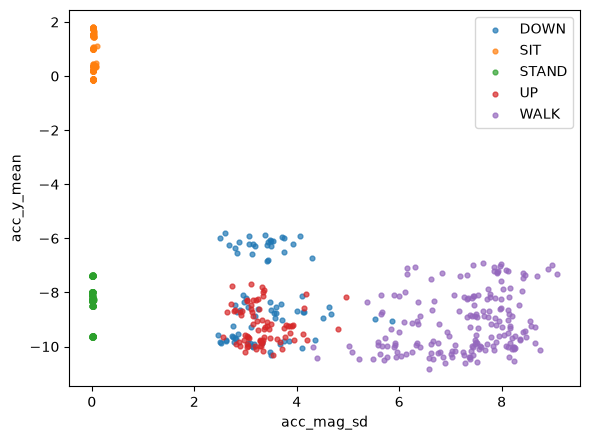

In [21]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for label, grp in features.groupby("label"):
    ax.scatter(grp["acc_mag_sd"], grp["acc_y_mean"], s=12, label=label, alpha=0.7)
ax.set_xlabel("acc_mag_sd")
ax.set_ylabel("acc_y_mean")
ax.legend()
plt.tight_layout()
plt.show()

### Review movement and inclination by recording

`groupby(['recording','label']).mean()` averages window summaries within each recording, making a compact development review table. The movement flag identifies a moving-labelled recording with very small acceleration variability and angular-speed magnitude. It is a prompt to investigate the protocol, not an automatic relabelling rule. Static classes can share magnitude while differing in inclination, and a reversed phone can change signs without changing the activity. No labels are changed by this review cell.


In [22]:
recording_summary = features.groupby(['recording','label'])[
    ['acc_x_mean','acc_y_mean','acc_z_mean','acc_mag_sd','gyr_mag_mean']].mean().reset_index()
recording_summary['review_flag'] = np.where(
    recording_summary.label.isin(['WALK','UP','DOWN']) &
    (recording_summary.acc_mag_sd < .10) & (recording_summary.gyr_mag_mean < .05),
    'very little motion for a moving label: review original protocol', '')
recording_summary.to_csv(ART/'tables/development_label_review.csv', index=False)
display(recording_summary.round(3))
print('Flags are prompts to review; no automatic relabelling or exclusion.')


,recording,label,acc_x_mean,acc_y_mean,acc_z_mean,acc_mag_sd,gyr_mag_mean,review_flag
0,DOWN_01,DOWN,4.970,-8.636,0.946,3.738,1.379,
1,DOWN_02,DOWN,1.649,-9.794,1.093,3.113,1.218,
2,DOWN_03,DOWN,7.546,-6.230,1.552,3.327,1.269,
3,SIT_01,SIT,9.375,0.365,2.796,0.039,0.018,
4,SIT_02,SIT,-9.674,1.014,1.554,0.024,0.010,
5,SIT_03,SIT,-8.416,1.522,4.909,0.026,0.014,
6,SIT_04,SIT,-8.366,0.199,5.222,0.017,0.004,
7,SIT_05,SIT,-9.763,-0.125,-1.315,0.022,0.006,
8,SIT_06,SIT,-9.605,1.760,-1.292,0.016,0.010,
9,SIT_07,SIT,-9.679,1.786,0.324,0.017,0.006,


Flags are prompts to review; no automatic relabelling or exclusion.


## 11 Model families training objectives and evaluation measures

The comparison uses **multinomial logistic regression (LR)** and **random forest (RF)**. They are different families: LR combines scaled features into linear class scores, while RF combines many decision trees with nonlinear rules and interactions. Both are evaluated on the same recording partitions and primary feature representation.

LR fits softmax probabilities by minimising multinomial log loss plus L2 regularisation. Schematically,

\[
L=-\frac{1}{N}\sum_n\log p(y_n\mid x_n)+\lambda\|W\|_F^2.
\]

A confidently wrong prediction is strongly penalised. Smaller `C` means stronger regularisation, which limits very large coefficients. The intercept is unpenalised in this configuration. `make_pipeline(StandardScaler(), LogisticRegression(...))` fits scaling inside each training fold, preventing validation/test information from entering the feature means or scales. `max_iter=3000` is an iteration limit, not a learning-rate setting.

RF uses 200 bootstrap trees with random subsets of features at splits. Its Gini criterion is `1 - sum(p_k**2)` within a node. Each split greedily reduces weighted child impurity; RF does not optimise one global loss equivalent to LR's objective. Depth and minimum leaf size control tree complexity. RF uses unscaled input features here. Do not assume the more complex model will win.

**Helper functions in the next cell:**

- `feature_columns(frame, mode)` explicitly selects predictor names starting with `acc_` or `gyr_`, then retains axes, magnitudes or both. This excludes labels, names, participant identity and times.
- `make_model(family, params)` constructs a fresh, unfitted estimator for a candidate. Every validation fold receives a fresh estimator through this function.
- `ordered_proba(model, X)` reorders probability columns from `model.classes_` into the fixed `ORDER`. Alphabetical estimator class order must not be assumed to match the clinical cost matrix.
- `decide(probabilities, rule)` returns either the largest-probability class or the class with lowest expected cost. It receives no true labels.
- `metrics(y_true, y_pred)` evaluates already-made predictions. It builds the confusion matrix, accuracy, macro F1, recall and observed cost, plus missed/false stair counts.

Precision of UP asks how many predicted-UP windows really are UP; UP recall asks how many true-UP windows were detected. F1 is their harmonic mean. Fixed-five-class macro F1 gives equal weight to the five F1 scores, despite 2:1 raw recording imbalance. The pipeline leaves model class weights at defaults and addresses imbalance through per-class reporting, macro F1 and cost-based selection. Class weights alone do not encode all asymmetric mistake costs.



In [23]:
COST = np.array([[0,1,1,3,3],
                 [1,0,1,3,3],
                 [1,1,0,3,3],
                 [10,10,10,0,2],
                 [10,10,10,2,0]], dtype=float)
display(pd.DataFrame(COST, index=pd.Index(ORDER, name='true'), columns=ORDER))

def feature_columns(frame, mode='both'):
    cols = [c for c in frame.columns if c.startswith(('acc_','gyr_'))]
    if mode == 'axes':
        cols = [c for c in cols if '_mag_' not in c]
    elif mode == 'magnitude':
        cols = [c for c in cols if '_mag_' in c]
    elif mode != 'both':
        raise ValueError(mode)
    return cols

def make_model(family, params):
    if family == 'LR':
        return make_pipeline(StandardScaler(), LogisticRegression(
            solver='lbfgs', C=params['C'], max_iter=3000, random_state=SEED))
    if family == 'RF':
        return RandomForestClassifier(n_estimators=200, criterion='gini',
            max_depth=params['max_depth'], min_samples_leaf=params['min_samples_leaf'],
            random_state=SEED, n_jobs=-1)
    raise ValueError(family)

def ordered_proba(model, X):
    probabilities = model.predict_proba(X)
    positions = [list(model.classes_).index(label) for label in ORDER]
    return probabilities[:, positions]

def decide(probabilities, rule):
    if rule == 'argmax':
        idx = probabilities.argmax(axis=1)
    elif rule == 'min_cost':
        idx = (probabilities @ COST).argmin(axis=1)
    else:
        raise ValueError(rule)
    return np.asarray(ORDER)[idx]

def metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    cm = confusion_matrix(y_true, y_pred, labels=ORDER)
    support = cm.sum(axis=1)
    recall = np.divide(np.diag(cm), support, out=np.full(5,np.nan), where=support>0)
    present = [k for k, s in zip(ORDER, support) if s > 0]
    index = {label:i for i,label in enumerate(ORDER)}
    costs = COST[[index[v] for v in y_true], [index[v] for v in y_pred]]
    true_stairs = np.isin(y_true, ['UP','DOWN'])
    pred_stairs = np.isin(y_pred, ['UP','DOWN'])
    result = dict(n_windows=len(y_true), classes_present=len(present), accuracy=accuracy_score(y_true,y_pred),
                  macro_f1=f1_score(y_true,y_pred,labels=ORDER,average='macro',zero_division=0),
                  macro_f1_present=f1_score(y_true,y_pred,labels=present,average='macro',zero_division=0),
                  mean_recall_present=float(np.nanmean(recall)), cost_per_1000=1000*costs.mean(),
                  missed_stair_windows=int((true_stairs & ~pred_stairs).sum()),
                  false_stair_windows=int((~true_stairs & pred_stairs).sum()))
    result.update({f'recall_{label}':float(value) for label,value in zip(ORDER,recall)})
    return result


,SIT,STAND,WALK,UP,DOWN
true,,,,,
SIT,0.0,1.0,1.0,3.0,3.0
STAND,1.0,0.0,1.0,3.0,3.0
WALK,1.0,1.0,0.0,3.0,3.0
UP,10.0,10.0,10.0,0.0,2.0
DOWN,10.0,10.0,10.0,2.0,0.0


## 13 Create validation folds without window leakage

`StratifiedKFold` is applied to a catalogue with **one row per development recording**. The resulting recording-to-fold dictionary is then used to select every window belonging to each recording. This is different from randomly splitting the feature-table rows.

Three folds are possible because the development set contains three recordings of each stair activity. Each validation fold therefore includes one UP and one DOWN recording. Counts of other activities differ slightly. `recording_folds.csv` makes assignments inspectable and reproducible.

**`grouped_folds(frame)`** maps each window's recording ID to its validation fold, obtains integer positions with `np.flatnonzero`, checks that training and validation have disjoint recording IDs and contain all five classes, then yields the row positions used by `.iloc`. `yield` provides one split at a time. The assertions stop the experiment if grouping or class coverage is broken.

All setting choices remain within development. A selected validation score is affected by the selection process and is not an independent generalisation estimate. The reserved recordings supply the final within-person test.


In [24]:
usable_recordings = sorted(features.recording.unique())
recordings_for_cv = dev_catalog[dev_catalog.recording.isin(usable_recordings)].sort_values('recording').reset_index(drop=True)
assert recordings_for_cv.groupby('label').size().reindex(ORDER,fill_value=0).min() >= 3, 'Need 3 usable development recordings in each class.'
fold_map = {}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
for fold, (_, validation_idx) in enumerate(cv.split(recordings_for_cv.recording, recordings_for_cv.label)):
    for recording in recordings_for_cv.iloc[validation_idx].recording:
        fold_map[recording] = fold
recordings_for_cv['validation_fold'] = recordings_for_cv.recording.map(fold_map)
recordings_for_cv.to_csv(ART/'tables/recording_folds.csv',index=False)
display(pd.crosstab(recordings_for_cv.label, recordings_for_cv.validation_fold).reindex(ORDER))

def grouped_folds(frame):
    folds = frame.recording.map(fold_map)
    assert folds.notna().all(), 'Unknown development recording'
    for fold in range(3):
        train_idx = np.flatnonzero(folds.ne(fold))
        valid_idx = np.flatnonzero(folds.eq(fold))
        assert set(frame.iloc[train_idx].recording).isdisjoint(frame.iloc[valid_idx].recording)
        assert set(frame.iloc[train_idx].label) == set(ORDER)
        assert set(frame.iloc[valid_idx].label) == set(ORDER)
        yield train_idx, valid_idx


validation_fold,0,1,2
label,,,
SIT,3,2,2
STAND,2,3,2
WALK,2,2,3
UP,1,1,1
DOWN,1,1,1


## 14 Search settings using development only

| Setting | Values |
|---|---|
| Window length | 2 or 3 s |
| Overlap | 0 or 0.5 |
| Representation | axes, magnitudes, both |
| LR regularisation C | 0.1, 1, 10 |
| RF maximum depth and minimum leaf size | (5,3), (10,3), (unlimited,1) |
| RF number of trees | 200, fixed |

The nested loops compare 12 preprocessing/representation settings and three parameter choices for each of two model families: **72 candidates and 216 validation fits**. Features are built once per length/overlap combination and reused for the candidate models. Cache reuse avoids re-reading unchanged raw files for cleaning.

For each candidate, a probability array initially contains NaNs. A fresh model is fitted on each training fold; `ordered_proba` writes predictions into the held-out fold's original row positions. When all three folds finish, every development window has one prediction from a model that did not train on its recording. An assertion checks the array is complete. Both decisions are evaluated on these out-of-fold probabilities.

**Selection rule declared before test:** within each setting/family choose lowest minimum-cost validation cost, break ties by higher macro F1 then candidate ID. Choose shared window/representation settings by the mean of the two selected family costs, then higher mean F1, fewer features, shorter windows and lower overlap. Shared primary inputs make the LR/RF comparison interpretable. `sort_values` and `drop_duplicates` implement these ordered choices.

The output ranks the shared settings and saves every candidate. Inspect the recorded setting rather than assuming the illustrative 2 s / 50% values will win. This search can take a few minutes on a CPU; there is no need for a GPU. Test results must not be used to revise the search after seeing its outcome.


In [25]:
PARAMS = {
    'LR':[{'C':0.1},{'C':1.0},{'C':10.0}],
    'RF':[{'max_depth':5,'min_samples_leaf':3},
          {'max_depth':10,'min_samples_leaf':3},
          {'max_depth':None,'min_samples_leaf':1}]
}
# Window configurations to evaluate on development data.
LENGTHS = [2.0, 2.5, 3.0]
OVERLAPS = [0.0, 0.5]
MODES = ['axes', 'magnitude', 'both']
development_tables, search_rows, candidates = {}, [], {}
candidate_number = 0
for length in LENGTHS:
    for overlap in OVERLAPS:
        frame, audit = build_feature_table(dev_catalog, length, overlap)
        if set(frame.recording) != set(recordings_for_cv.recording):
            raise ValueError('Candidate configurations must use the same usable recordings.')
        development_tables[(length,overlap)] = frame
        for mode in MODES:
            cols = feature_columns(frame, mode)
            X, y = frame[cols], frame.label.to_numpy()
            assert np.isfinite(X.to_numpy()).all()
            for family in ['LR','RF']:
                for params in PARAMS[family]:
                    candidate_number += 1
                    key = f'candidate_{candidate_number:03d}'
                    probability = np.full((len(frame),len(ORDER)),np.nan)
                    for train_idx, valid_idx in grouped_folds(frame):
                        model = make_model(family, params)
                        model.fit(X.iloc[train_idx], y[train_idx])
                        probability[valid_idx] = ordered_proba(model, X.iloc[valid_idx])
                    assert np.isfinite(probability).all()
                    details = dict(candidate=key, length=length, overlap=overlap, mode=mode,
                                   n_features=len(cols), family=family, params_json=json.dumps(params,sort_keys=True))
                    for rule in ['argmax','min_cost']:
                        search_rows.append(dict(details,rule=rule,**metrics(y,decide(probability,rule))))
                    candidates[key] = dict(details,params=deepcopy(params))
        print(f'Completed development validation: length={length}, overlap={overlap}',flush=True)
search = pd.DataFrame(search_rows)
search.to_csv(ART/'tables/validation_all_candidates.csv',index=False)
clinical_search = search[search.rule.eq('min_cost')].sort_values(
    ['cost_per_1000','macro_f1','candidate'],ascending=[True,False,True])
best_per_setting = clinical_search.drop_duplicates(['length','overlap','mode','family'])
settings = best_per_setting.groupby(['length','overlap','mode','n_features']).agg(
    mean_cost=('cost_per_1000','mean'), mean_macro_f1=('macro_f1','mean'), families=('family','nunique')).reset_index()
settings = settings[settings.families.eq(2)].sort_values(
    ['mean_cost','mean_macro_f1','n_features','length','overlap'],ascending=[True,False,True,True,True])
settings.to_csv(
    ART/'tables/validation_shared_settings.csv',
    index=False
)
display(settings.round(4))


Completed development validation: length=2.0, overlap=0.0
Completed development validation: length=2.0, overlap=0.5
Completed development validation: length=2.5, overlap=0.0
Completed development validation: length=2.5, overlap=0.5
Completed development validation: length=3.0, overlap=0.0
Completed development validation: length=3.0, overlap=0.5


,length,overlap,mode,n_features,mean_cost,mean_macro_f1,families
13,3.0,0.0,both,40,67.9012,0.9672,2
16,3.0,0.5,both,40,76.2527,0.9648,2
7,2.5,0.0,both,40,79.1246,0.9621,2
11,2.5,0.5,magnitude,10,96.1199,0.9249,2
14,3.0,0.0,magnitude,10,98.7654,0.9321,2
17,3.0,0.5,magnitude,10,101.3072,0.9246,2
5,2.0,0.5,magnitude,10,103.8136,0.9331,2
10,2.5,0.5,both,40,108.4656,0.9545,2
8,2.5,0.0,magnitude,10,114.4781,0.9132,2
1,2.0,0.0,both,40,117.6471,0.9554,2


Choose these values after reviewing the validation table.

In [26]:
# Choose these values after reviewing the validation table.
BEST_LENGTH = 3.0       # 2.0 or 2.5 or 3.0 seconds
BEST_OVERLAP = 0.0      # 0.0 or 0.5
BEST_MODE = 'both'      # 'axes', 'magnitude' or 'both'

manual_choice = settings[
    settings.length.eq(BEST_LENGTH)
    & settings.overlap.eq(BEST_OVERLAP)
    & settings['mode'].eq(BEST_MODE)
]

if manual_choice.empty:
    raise ValueError(
        'Choose a configuration included in the validation table.'
    )

selected = manual_choice.iloc[0]

print(
    'Manually selected on development only:',
    BEST_LENGTH, BEST_OVERLAP, BEST_MODE
)
display(manual_choice.round(4))

Manually selected on development only: 3.0 0.0 both


,length,overlap,mode,n_features,mean_cost,mean_macro_f1,families
13,3.0,0.0,both,40,67.9012,0.9672,2


In [27]:
# Review model parameters for the selected window configuration.
parameter_options = clinical_search.loc[
    clinical_search.length.eq(BEST_LENGTH)
    & clinical_search.overlap.eq(BEST_OVERLAP)
    & clinical_search['mode'].eq(BEST_MODE)
].copy()

display(
    parameter_options[
        ['family', 'params_json', 'cost_per_1000', 'macro_f1',
         'recall_UP', 'recall_DOWN']
    ]
    .sort_values(['family', 'cost_per_1000'])
    .round(4)
)

,family,params_json,cost_per_1000,macro_f1,recall_UP,recall_DOWN
169,LR,"{""C"": 0.1}",49.3827,0.9704,1.0,1.0
171,LR,"{""C"": 1.0}",111.1111,0.9509,1.0,1.0
173,LR,"{""C"": 10.0}",135.8025,0.9475,1.0,1.0
175,RF,"{""max_depth"": 5, ""min_samples_leaf"": 3}",86.4198,0.9639,1.0,1.0
177,RF,"{""max_depth"": 10, ""min_samples_leaf"": 3}",86.4198,0.9639,1.0,1.0
179,RF,"{""max_depth"": null, ""min_samples_leaf"": 1}",86.4198,0.9639,1.0,1.0


# Choose these values after reviewing the validation table.


In [28]:
# Choose these values after reviewing the validation table.
LR_C = 0.1
RF_MAX_DEPTH = 5
RF_MIN_SAMPLES_LEAF = 3

MANUAL_PARAMS = {
    'LR': {
        'C': float(LR_C)
    },
    'RF': {
        'max_depth': RF_MAX_DEPTH,
        'min_samples_leaf': RF_MIN_SAMPLES_LEAF
    }
}

# Locate the validation results for the chosen parameters.
wanted_json = {
    family: json.dumps(params, sort_keys=True)
    for family, params in MANUAL_PARAMS.items()
}

manual_validation = parameter_options.loc[
    parameter_options.params_json.eq(
        parameter_options.family.map(wanted_json)
    )
].copy()

# Require one previously evaluated configuration per model family.
if (
    len(manual_validation) != 2
    or set(manual_validation.family) != {'LR', 'RF'}
):
    raise ValueError(
        'Choose parameter combinations evaluated in section 14. '
        'For new combinations, update PARAMS and rerun section 14.'
    )

display(
    manual_validation[
        ['family', 'params_json', 'cost_per_1000', 'macro_f1']
    ].round(4)
)

print(
    'Mean validation cost for the manual models:',
    manual_validation.cost_per_1000.mean()
)

,family,params_json,cost_per_1000,macro_f1
169,LR,"{""C"": 0.1}",49.3827,0.9704
175,RF,"{""max_depth"": 5, ""min_samples_leaf"": 3}",86.4198,0.9639


Mean validation cost for the manual models: 67.90123456790123


## 15 Freeze the settings and fit the final development models

The chosen length, overlap and primary representation are now fixed. For each family, the code also retains separately validated axes-only, magnitude-only and combined variants for the prespecified feature ablation. Each variant is fitted on all usable development windows and stored with its ordered feature list, settings and primary/not-primary flag.

`joblib.dump` saves these fitted objects. `frozen_config.json` records cleaning rules, label order, the cost matrix, model settings, random seed, package versions and the recording split **before held-out results are calculated**. Reusing a saved scaler is part of reusing LR; fitting a new scaler on another participant would change the system.

The validation table shown here compares the two decision rules for the selected models. These values are useful for understanding selection and clinical trade-offs, but they are still development results. The other variants were planned before testing; their test results must not retrospectively change the chosen primary representation.


In [29]:
final_dev = development_tables[(BEST_LENGTH, BEST_OVERLAP)]
frozen_variants, selected_candidates = {}, []

for family in ['LR', 'RF']:
    for mode in MODES:
        available = clinical_search.loc[
            clinical_search.family.eq(family)
            & clinical_search['mode'].eq(mode)
            & clinical_search.length.eq(BEST_LENGTH)
            & clinical_search.overlap.eq(BEST_OVERLAP)
        ]

        # Apply manual parameters to the primary representation.
        if mode == BEST_MODE:
            params_key = json.dumps(
                MANUAL_PARAMS[family], sort_keys=True
            )
            available = available.loc[
                available.params_json.eq(params_key)
            ]

        if available.empty:
            raise ValueError(
                'No validated candidate: rerun the manual selection cells.'
            )

        winner = available.iloc[0]

        # Recover the configuration from the selected validation row.
        config = winner[
            ['candidate', 'length', 'overlap', 'mode',
             'n_features', 'family', 'params_json']
        ].to_dict()

        config['params'] = json.loads(config['params_json'])

        cols = feature_columns(final_dev, mode)

        fitted = make_model(
            family, config['params']
        ).fit(final_dev[cols], final_dev.label)

        variant = dict(
            model=fitted,
            columns=cols,
            config=config,
            primary=(mode == BEST_MODE)
        )

        frozen_variants[(family, mode)] = variant
        joblib.dump(variant, ART / 'models' / f'{family}_{mode}.joblib')

        selected_candidates.append(
            dict(
                config,
                primary=(mode == BEST_MODE),
                validation_cost=float(winner.cost_per_1000),
                validation_macro_f1=float(winner.macro_f1)
            )
        )

frozen_config = dict(
    cleaning=CLEANING,
    seed=SEED,
    class_order=ORDER,
    cost_matrix=COST.tolist(),
    window_length=BEST_LENGTH,
    overlap=BEST_OVERLAP,
    primary_mode=BEST_MODE,
    selection_criterion=(
        'manual primary settings and parameters; '
        'auxiliary representations selected by development validation'
    ),
    variants=selected_candidates,
    versions=VERSIONS,
    development_recordings=sorted(final_dev.recording.unique()),
    reserved_test_recordings=sorted(test_catalog.recording.unique())
)

(ART / 'frozen_config.json').write_text(
    json.dumps(frozen_config, indent=2),
    encoding='utf-8'
)

display(
    pd.DataFrame(selected_candidates)[
        ['family', 'mode', 'params_json', 'primary',
         'validation_cost', 'validation_macro_f1']
    ].round(4)
)

primary_candidate_ids = [
    v['candidate'] for v in selected_candidates if v['primary']
]

validation_selected = search[
    search.candidate.isin(primary_candidate_ids)
].copy()

validation_selected.to_csv(
    ART / 'tables' / 'validation_selected_models.csv',
    index=False
)

display(
    validation_selected[
        ['family', 'rule', 'macro_f1', 'cost_per_1000']
    ].round(4)
)


,family,mode,params_json,primary,validation_cost,validation_macro_f1
0,LR,axes,"{""C"": 10.0}",False,135.8025,0.9475
1,LR,magnitude,"{""C"": 10.0}",False,102.8807,0.9299
2,LR,both,"{""C"": 0.1}",True,49.3827,0.9704
3,RF,axes,"{""max_depth"": 5, ""min_samples_leaf"": 3}",False,135.8025,0.9441
4,RF,magnitude,"{""max_depth"": 5, ""min_samples_leaf"": 3}",False,94.6502,0.9343
5,RF,both,"{""max_depth"": 5, ""min_samples_leaf"": 3}",True,86.4198,0.9639


,family,rule,macro_f1,cost_per_1000
168,LR,argmax,0.9756,65.8436
169,LR,min_cost,0.9704,49.3827
174,RF,argmax,0.9893,82.3045
175,RF,min_cost,0.9639,86.4198


## 16 Experiment 1 reserved own recordings

The reserved recordings now pass through the already-fixed cleaning and feature pipeline. Quality failures are logged; preprocessing is not retuned in response to their mistakes. The disjoint-ID assertion checks the recording boundary again.

**`evaluate_variants(frame, scope, person)`** receives a labelled feature table and descriptive output names. It loops over the six frozen model/representation variants, selects the stored columns, obtains ordered probabilities, and evaluates both decision rules. No model fitting occurs inside this function. It returns three tables: aggregate metrics, predictions/probabilities for each window, and per-class precision/recall/F1/support. For each primary model and each rule it saves the confusion matrix as CSV and PNG. The identifier fields accompany predictions for auditing, not as predictors.

\[
\text{Observed cost per 1,000 windows}=\frac{1000}{N}\sum_n C(y_n,\hat y_n).
\]

This is a normalised count of assignment cost units, not money, patients or independently observed stair bouts. Per-class support and the number of independent recordings should accompany window counts. Neighbouring windows from a recording can remain correlated even without overlap. A perfect result on these own recordings does not establish cross-person or clinical validity.


In [30]:
def evaluate_variants(frame, scope, person):
    rows, predictions, per_class = [], [], []
    scope_dir = ART/'figures'/scope
    scope_dir.mkdir(parents=True,exist_ok=True)
    for (family,mode), variant in frozen_variants.items():
        probabilities = ordered_proba(variant['model'],frame[variant['columns']])
        for rule in ['argmax','min_cost']:
            pred = decide(probabilities,rule)
            rows.append(dict(scope=scope,person=person,family=family,mode=mode,rule=rule,
                             primary=variant['primary'],**metrics(frame.label,pred)))
            pred_frame = frame[['recording','code','label','window','start','end']].copy()
            pred_frame = pred_frame.assign(person=person,family=family,mode=mode,rule=rule,prediction=pred)
            for k,label in enumerate(ORDER):
                pred_frame[f'p_{label}'] = probabilities[:,k]
            predictions.append(pred_frame)
            report = classification_report(frame.label,pred,labels=ORDER,output_dict=True,zero_division=0)
            for label in ORDER:
                per_class.append(dict(person=person,family=family,mode=mode,rule=rule,label=label,**report[label]))
            if variant['primary']:
                cm = confusion_matrix(frame.label,pred,labels=ORDER)
                pd.DataFrame(cm,index=ORDER,columns=ORDER).to_csv(
                    ART/'tables'/f'{scope}_{person}_{family}_{rule}_confusion.csv')
                fig, ax = plt.subplots(figsize=(5.4,4.4))
                ConfusionMatrixDisplay(cm,display_labels=ORDER).plot(ax=ax,colorbar=False,cmap='Blues')
                ax.set_title(f'{person} · {family} · {rule}')
                fig.tight_layout()
                fig.savefig(scope_dir/f'{person}_{family}_{rule}_confusion.png',dpi=160)
                plt.close(fig)
    return pd.DataFrame(rows),pd.concat(predictions,ignore_index=True),pd.DataFrame(per_class)

test_features,test_audit = build_feature_table(test_catalog,BEST_LENGTH,BEST_OVERLAP)
test_audit.to_csv(ART/'tables/test_cleaning_audit.csv',index=False)
assert not test_features.empty,'No usable test windows; report data quality before evaluating.'
assert set(test_features.recording).isdisjoint(final_dev.recording)
test_results,test_predictions,test_class_metrics = evaluate_variants(test_features,'within_person','own_holdout')
test_results.to_csv(ART/'tables/within_person_all_variants.csv',index=False)
test_predictions.to_csv(ART/'tables/within_person_window_predictions.csv',index=False)
test_class_metrics.to_csv(ART/'tables/within_person_per_class.csv',index=False)
primary_results = test_results[test_results.primary].copy()
primary_results.to_csv(ART/'tables/within_person_primary.csv',index=False)
display(primary_results[['family','rule','n_windows','accuracy','macro_f1','cost_per_1000',
                         'recall_UP','recall_DOWN','missed_stair_windows','false_stair_windows']].round(4))
display(test_class_metrics[test_class_metrics['mode'].eq(BEST_MODE)].round(4))


,family,rule,n_windows,accuracy,macro_f1,cost_per_1000,recall_UP,recall_DOWN,missed_stair_windows,false_stair_windows
4,LR,argmax,117,1.0,1.0,0.0,1.0,1.0,0,0
5,LR,min_cost,117,1.0,1.0,0.0,1.0,1.0,0,0
10,RF,argmax,117,1.0,1.0,0.0,1.0,1.0,0,0
11,RF,min_cost,117,1.0,1.0,0.0,1.0,1.0,0,0


,person,family,mode,rule,label,precision,recall,f1-score,support
20,own_holdout,LR,both,argmax,SIT,1.0,1.0,1.0,27.0
21,own_holdout,LR,both,argmax,STAND,1.0,1.0,1.0,27.0
22,own_holdout,LR,both,argmax,WALK,1.0,1.0,1.0,27.0
23,own_holdout,LR,both,argmax,UP,1.0,1.0,1.0,18.0
24,own_holdout,LR,both,argmax,DOWN,1.0,1.0,1.0,18.0
25,own_holdout,LR,both,min_cost,SIT,1.0,1.0,1.0,27.0
26,own_holdout,LR,both,min_cost,STAND,1.0,1.0,1.0,27.0
27,own_holdout,LR,both,min_cost,WALK,1.0,1.0,1.0,27.0
28,own_holdout,LR,both,min_cost,UP,1.0,1.0,1.0,18.0
29,own_holdout,LR,both,min_cost,DOWN,1.0,1.0,1.0,18.0


### Read confusion matrices and decision-rule differences

Rows are true activities and columns are predicted activities. Diagonal cells are correct. A true UP predicted as WALK costs 10, whereas UP predicted as DOWN costs 2. These are different errors even though both reduce accuracy.

The four-panel figure presents both primary models under both decision rules. The effect table subtracts argmax performance from minimum-cost performance: a negative cost difference is a reduction, while a negative accuracy or F1 difference is a decline. A zero difference is a valid observation, not a reason to invent a threshold adjustment after inspecting test results.

`test_per_recording.csv` groups saved predictions by source recording and reports their outcomes. This helps distinguish widespread errors from many correlated errors in one take. Preserve and explain any deterioration instead of reporting only a favourable metric.


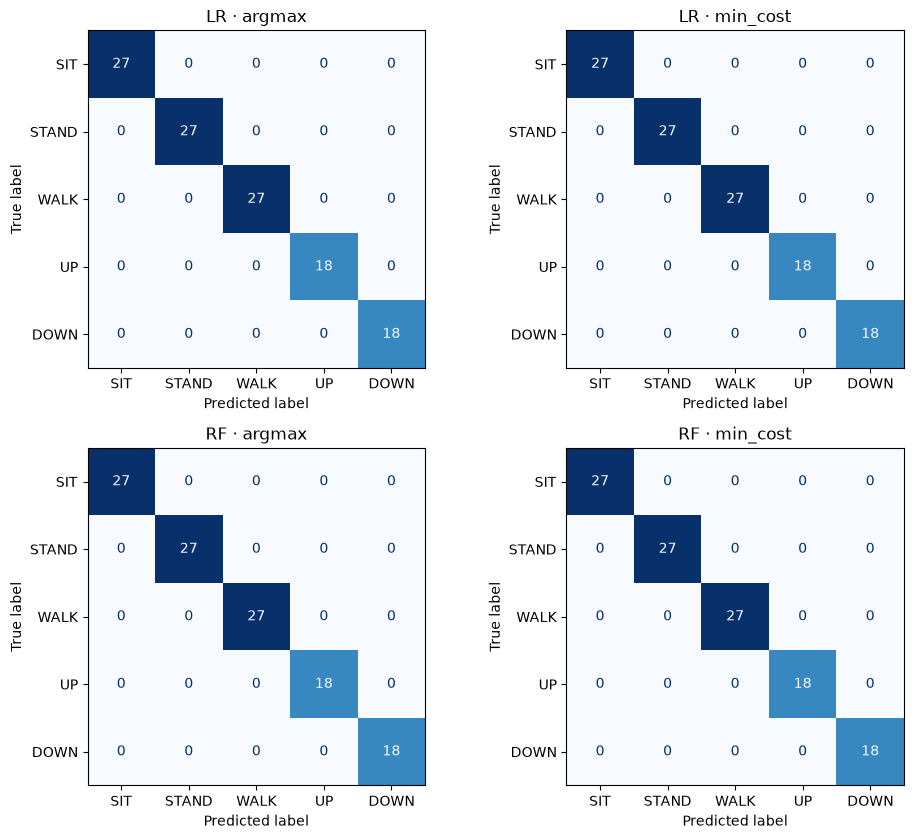

,family,delta_cost_per_1000,delta_accuracy,delta_macro_f1,delta_recall_UP,delta_recall_DOWN
0,LR,0.0,0.0,0.0,0.0,0.0
1,RF,0.0,0.0,0.0,0.0,0.0


In [31]:
fig, axes = plt.subplots(2,2,figsize=(10,8.5))
for row,family in enumerate(['LR','RF']):
    for col,rule in enumerate(['argmax','min_cost']):
        pred = test_predictions[test_predictions.family.eq(family)&test_predictions['mode'].eq(BEST_MODE)&test_predictions.rule.eq(rule)]
        cm = confusion_matrix(pred.label,pred.prediction,labels=ORDER)
        ConfusionMatrixDisplay(cm,display_labels=ORDER).plot(ax=axes[row,col],colorbar=False,cmap='Blues')
        axes[row,col].set_title(f'{family} · {rule}')
fig.tight_layout()
fig.savefig(ART/'figures/03_within_person_confusions.png',dpi=160)
plt.show()

effect = []
for family,grp in primary_results.groupby('family'):
    a,b = grp.set_index('rule').loc['argmax'],grp.set_index('rule').loc['min_cost']
    effect.append(dict(family=family,delta_cost_per_1000=b.cost_per_1000-a.cost_per_1000,
                       delta_accuracy=b.accuracy-a.accuracy,delta_macro_f1=b.macro_f1-a.macro_f1,
                       delta_recall_UP=b.recall_UP-a.recall_UP,delta_recall_DOWN=b.recall_DOWN-a.recall_DOWN))
effect = pd.DataFrame(effect)
effect.to_csv(ART/'tables/decision_rule_effect.csv',index=False)
display(effect.round(4))
per_recording = []
for (family,mode,rule,recording),grp in test_predictions.groupby(['family','mode','rule','recording']):
    per_recording.append(dict(family=family,mode=mode,rule=rule,recording=recording,**metrics(grp.label,grp.prediction)))
pd.DataFrame(per_recording).to_csv(ART/'tables/test_per_recording.csv',index=False)


## 17 Compare axes magnitudes and combined features

The ablation uses the selected window settings and parameters chosen for each representation using development only. Each representation is fitted on development and then evaluated on the same held-out recordings. The primary flag identifies the representation already chosen before test evaluation.

The table reports accuracy-related measures, class recalls and clinical cost; the bar chart displays cost for the minimum-cost rule. Zero-height bars mean zero observed cost. They do not indicate a missing experiment.

Magnitude retains movement size under a rotation of the coordinate system but loses directional gravity information useful for posture. Axes retain that information and can also be sensitive to placement. Compare both own-person and across-person results before deciding which transfers better. If axes alone and combined features tie on a small test, the tie does not prove that every added magnitude statistic is necessary.


,family,mode,primary,macro_f1,cost_per_1000,recall_SIT,recall_STAND,recall_UP,recall_DOWN
1,LR,axes,False,1.0000,0.0000,1.0,1.0000,1.0000,1.0000
3,LR,magnitude,False,0.8389,170.9402,1.0,0.3333,1.0000,0.9444
5,LR,both,True,1.0000,0.0000,1.0,1.0000,1.0000,1.0000
7,RF,axes,False,1.0000,0.0000,1.0,1.0000,1.0000,1.0000
9,RF,magnitude,False,0.7586,290.5983,1.0,0.3333,0.9444,0.6111
11,RF,both,True,1.0000,0.0000,1.0,1.0000,1.0000,1.0000


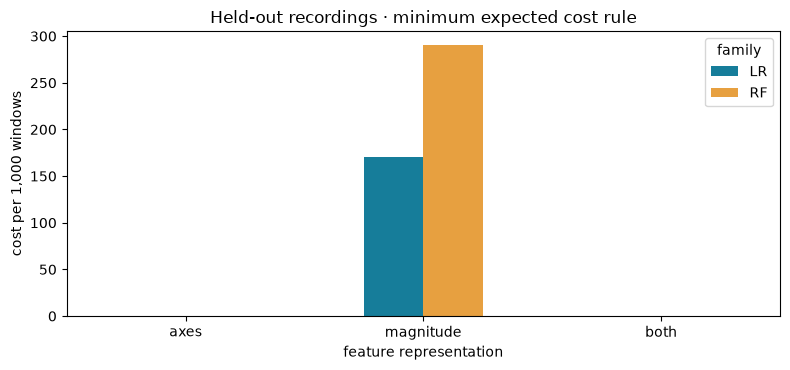

In [32]:
ablation = test_results[test_results.rule.eq('min_cost')].copy()
display(ablation[['family','mode','primary','macro_f1','cost_per_1000','recall_SIT','recall_STAND','recall_UP','recall_DOWN']].round(4))
fig, ax = plt.subplots(figsize=(8,3.8))
ablation.pivot(index='mode',columns='family',values='cost_per_1000').reindex(MODES).plot.bar(ax=ax,color=['#167d9a','#e7a040'])
ax.set(xlabel='feature representation',ylabel='cost per 1,000 windows',title='Held-out recordings · minimum expected cost rule')
ax.tick_params(axis='x',rotation=0)
fig.tight_layout()
fig.savefig(ART/'figures/04_feature_ablation.png',dpi=160)
plt.show()


In [33]:
pool_files = sorted(POOL_DIR.rglob("*.zip"))
print("ZIP recordings found:", len(pool_files))

for path in pool_files[:10]:
    print(path.relative_to(POOL_DIR))

ZIP recordings found: 160
S01\S01_DOWN_01.zip
S01\S01_DOWN_02.zip
S01\S01_DOWN_03.zip
S01\S01_DOWN_04.zip
S01\S01_DOWN_05.zip
S01\S01_SIT_01.zip
S01\S01_SIT_02.zip
S01\S01_SIT_03.zip
S01\S01_SIT_04.zip
S01\S01_SIT_05.zip


In [34]:
folder = POOL_DIR / "S02"
renames = []

for path in sorted(folder.rglob("*.zip")):
    info = parse_name(path)

    # Only change recognized recordings that do not yet have a prefix.
    if info is not None and info["code"] == "me":
        target = path.with_name("S02_" + path.name)

        if target.exists():
            raise FileExistsError(f"El archivo ya existe: {target}")

        renames.append((path, target))

# Rename after checking that there are no conflicts.
for source, target in renames:
    source.rename(target)

print("Renamed recordings:", len(renames))
for path in sorted(folder.rglob("*.zip"))[:5]:
    print(path.name)

Renamed recordings: 0
S02_DOWN_01.zip
S02_DOWN_02.zip
S02_DOWN_03.zip
S02_DOWN_04.zip
S02_DOWN_05.zip


In [35]:
print("Pool used:", POOL_DIR.resolve())

renames = []

for folder in sorted(POOL_DIR.iterdir()):
    if not folder.is_dir() or not folder.name.startswith("S"):
        continue

    zips = sorted(folder.rglob("*.zip"))
    detected_codes = set()

    print(f"{folder.name}: {len(zips)} archivos ZIP")

    for path in zips:
        info = parse_name(path)

        if info is None:
            detected_codes.add("unrecognised filename")
            continue

        detected_codes.add(info["code"])

        # Add the folder's participant code only when no prefix exists.
        if info["code"] == "me":
            target = path.with_name(f"{folder.name}_{path.name}")

            if target.exists():
                raise FileExistsError(
                    f"Name collision: {target}. Review these files."
                )

            renames.append((path, target))

    print("Codes detected before correction:", sorted(detected_codes))

# Rename only after checking all destination names.
for source, target in renames:
    source.rename(target)

print("ZIPs renamed:", len(renames))

Pool used: C:\Users\ektor\OneDrive\Escritorio\ATU\Machine Learning\_Assigment_ML_Cuenca\data\pool
S01: 40 archivos ZIP
Codes detected before correction: ['S01']
S02: 40 archivos ZIP
Codes detected before correction: ['S02']
S03: 40 archivos ZIP
Codes detected before correction: ['S03']
S04: 40 archivos ZIP
Codes detected before correction: ['S04']
ZIPs renamed: 0


## 18 Experiment 2 the real class pool without refitting

Place anonymous files such as `S03_UP_03.zip` or `S07_1_STAND_02.zip` in `data/pool`. If no files are present, the function writes a pending status and produces no scientific cross-person result. The actual pool has not yet been provided in this project.

**`run_pool()`** builds a catalogue, rejects unprefixed pool names, removes within-person duplicates/conflicts, and applies the identical cleaning/feature rules. It passes each person's usable table to `evaluate_variants`; no `.fit()` occurs in this section. It saves per-person metrics, per-class reports, both primary confusion matrices for both decisions, feature ablations, exclusions, label-review flags and device metadata.

**Identity evidence:** own and pooled sensor-content fingerprints are joined. Matching-file names and labels are saved, including whether own development or own held-out files matched. One uniquely matching anonymous code is a candidate to verify from the saved evidence; no matches or multiple candidates leave identity unresolved. Good accuracy is not identity evidence. A match should be reviewed as numerical-content evidence, and copied or misattributed pool files can complicate attribution.

**Person-level exclusion:** any participant with a match to an own recording is excluded from the summary of new people, including a match only to an own held-out recording. A held-out recording from the training person is not a new participant. The existing summary-field name `independent_of_development` is retained for compatibility, but True means no own-file match was detected, not proof of a distinct person. Confirm anonymous identities before making a final new-person claim.

The saved per-person tables remain the primary evidence. The summary mean gives equal weight to eligible people; it is different from pooling all windows, which would weight people with more recordings more heavily. Missing classes and unusable files must be reported, and settings must not be adapted to pool performance.


In [36]:
def run_pool():
    paths = list(POOL_DIR.rglob('*.zip'))
    if not paths:
        print('PENDING: no pooled recordings supplied. No across-person result or anonymous identity can be reported yet.')
        (ART/'pool_status.json').write_text(json.dumps({'status':'pending','reason':'No pool provided'},indent=2))
        return pd.DataFrame(),pd.DataFrame()
    catalog = build_catalog(paths)
    if 'code' not in catalog:
        catalog.to_csv(ART/'tables/pool_manifest.csv',index=False)
        print('PENDING: no recognised pooled recording names.')
        return pd.DataFrame(),pd.DataFrame()
    no_code = catalog.code.eq('me') & catalog.eligible
    catalog.loc[no_code,['eligible','reason']] = [False,'pool recording has no anonymous person prefix']
    catalog.to_csv(ART/'tables/pool_manifest.csv',index=False)
    accepted = catalog[catalog.eligible].copy()
    own_refs = own_catalog[own_catalog.eligible][['file','label','signature','split']].rename(
        columns={'file':'own_file','label':'own_label','split':'own_split'})
    matches = accepted.merge(own_refs,on='signature',how='inner')
    matches.to_csv(ART/'tables/pool_identity_evidence.csv',index=False)
    identity = matches.groupby('code').agg(matched_files=('file','nunique'),
        matching_development=('own_split',lambda s:int(s.eq('development').sum()))).reset_index() if not matches.empty else pd.DataFrame(columns=['code','matched_files','matching_development'])
    identity.to_csv(ART/'tables/pool_identity_candidates.csv',index=False)
    display(identity)
    if len(identity) == 1:
        print('Unique exact-content identity candidate:',identity.iloc[0].code,'; inspect the saved matches as evidence.')
    else:
        print('Identity unresolved: need unique verified matches or lecturer mapping; do not guess.')
    all_results,all_predictions,all_class_metrics,all_audits,review_rows,device_rows = [],[],[],[],[],[]
    for person,group in accepted.groupby('code'):
        frame,audit = build_feature_table(group,BEST_LENGTH,BEST_OVERLAP)
        audit['person'] = person
        all_audits.append(audit)
        if frame.empty:
            print('No usable windows for',person,'; see audit.')
            continue
        result,predictions,class_metrics = evaluate_variants(frame,'across_person',person)
        person_matches = matches[matches.code.eq(person)]
        overlap_train = int(person_matches.own_split.eq('development').sum())
        result['matching_own_files'] = int(person_matches.file.nunique())
        result['matching_development_files'] = overlap_train
        result['independent_of_development'] = person_matches.empty
        all_results.append(result);all_predictions.append(predictions);all_class_metrics.append(class_metrics)
        summary = frame.groupby(['recording','label'])[
            ['acc_x_mean','acc_y_mean','acc_z_mean','acc_mag_mean','acc_mag_sd','gyr_mag_mean']].mean().reset_index()
        summary['person'] = person
        summary['review_flag'] = np.where(summary.label.isin(['UP','DOWN','WALK']) &
            summary.acc_mag_sd.lt(.10) & summary.gyr_mag_mean.lt(.05),'very little motion for moving label: verify protocol','')
        review_rows.append(summary)
        for item in group.to_dict('records'):
            try:
                metadata = read_meta(Path(item['path']),'device')
                values = dict(zip(metadata.iloc[:,0].astype(str),metadata.iloc[:,1].astype(str)))
                device_rows.append(dict(person=person,file=item['file'],deviceModel=values.get('deviceModel','unknown'),
                                        deviceBrand=values.get('deviceBrand','unknown')))
            except Exception as exc:
                device_rows.append(dict(person=person,file=item['file'],metadata_error=str(exc)))
    if all_audits:
        pd.concat(all_audits,ignore_index=True).to_csv(ART/'tables/pool_cleaning_audit.csv',index=False)
    if not all_results:
        print('No usable pool results. See manifest and cleaning audit.')
        return pd.DataFrame(),matches
    results = pd.concat(all_results,ignore_index=True)
    results.to_csv(ART/'tables/across_person_all_variants.csv',index=False)
    pd.concat(all_predictions,ignore_index=True).to_csv(ART/'tables/across_person_predictions.csv',index=False)
    pd.concat(all_class_metrics,ignore_index=True).to_csv(ART/'tables/across_person_per_class.csv',index=False)
    pd.concat(review_rows,ignore_index=True).to_csv(ART/'tables/pool_label_review.csv',index=False)
    pd.DataFrame(device_rows).to_csv(ART/'tables/pool_device_inventory.csv',index=False)
    primary = results[results.primary].copy()
    primary.to_csv(ART/'tables/across_person_primary.csv',index=False)
    # Average people equally; also preserve per-person results and missing-class coverage.
    independent = primary[primary.independent_of_development]
    independent.groupby(['family','rule'])[['accuracy','macro_f1','cost_per_1000']].mean().to_csv(
        ART/'tables/across_person_independent_mean.csv')
    (ART/'pool_status.json').write_text(json.dumps({'status':'processed','persons_evaluated':int(primary.person.nunique()),
        'identity_candidates':identity.code.tolist(),'note':'Inspect identity and overlap evidence before claiming person independence.'},indent=2))
    display(primary[['person','family','rule','n_windows','classes_present','accuracy','macro_f1',
                     'cost_per_1000','matching_development_files']].round(4))
    display(primary[primary.rule.eq('min_cost')].sort_values('cost_per_1000',ascending=False).head(6))
    return results,matches

pool_results,pool_matches = run_pool()


,code,matched_files,matching_development
0,S01,40,27


Unique exact-content identity candidate: S01 ; inspect the saved matches as evidence.


,person,family,rule,n_windows,classes_present,accuracy,macro_f1,cost_per_1000,matching_development_files
4,S01,LR,argmax,360,5,1.0000,1.0000,0.0000,27
5,S01,LR,min_cost,360,5,0.9972,0.9967,8.3333,27
10,S01,RF,argmax,360,5,1.0000,1.0000,0.0000,27
11,S01,RF,min_cost,360,5,0.9972,0.9967,8.3333,27
16,S02,LR,argmax,360,5,0.4556,0.3581,2780.5556,0
17,S02,LR,min_cost,360,5,0.4278,0.3322,2569.4444,0
22,S02,RF,argmax,360,5,0.3806,0.2820,2544.4444,0
23,S02,RF,min_cost,360,5,0.3861,0.2796,2236.1111,0
28,S03,LR,argmax,315,5,0.4698,0.4013,1495.2381,0
29,S03,LR,min_cost,315,5,0.4762,0.4189,1323.8095,0


,scope,person,family,mode,rule,primary,n_windows,classes_present,accuracy,macro_f1,...,missed_stair_windows,false_stair_windows,recall_SIT,recall_STAND,recall_WALK,recall_UP,recall_DOWN,matching_own_files,matching_development_files,independent_of_development
17,across_person,S02,LR,both,min_cost,True,360,5,0.427778,0.332171,...,60,83,0.500000,1.0,0.022222,0.244444,0.133333,0,0,True
23,across_person,S02,RF,both,min_cost,True,360,5,0.386111,0.279576,...,42,90,0.300000,1.0,0.000000,0.044444,0.444444,0,0,True
29,across_person,S03,LR,both,min_cost,True,315,5,0.476190,0.418882,...,1,89,0.833333,1.0,0.000000,0.277778,0.111111,0,0,True
47,across_person,S04,RF,both,min_cost,True,360,5,0.400000,0.260963,...,0,87,0.100000,1.0,0.000000,0.000000,1.000000,0,0,True
41,across_person,S04,LR,both,min_cost,True,360,5,0.463889,0.379289,...,6,84,0.100000,1.0,0.000000,0.688889,0.822222,0,0,True
35,across_person,S03,RF,both,min_cost,True,315,5,0.549206,0.487096,...,0,89,1.000000,1.0,0.000000,0.194444,0.488889,0,0,True


### Compare participants and investigate difficult cases

When real pool results exist, the following cell plots accuracy and cost by participant and family using minimum-cost decisions. Complete per-person confusion matrices remain available in `artifacts/figures/across_person` and the CSV outputs. Inspect the predeclared representation variants to assess whether axes or magnitudes transfer better.

A low-accuracy participant and a high-cost participant need not be the same person. Use the confusion matrix to distinguish missed stairs, false stair alarms and UP–DOWN swaps. Relate differences to measured signal variability, orientation, sampling and documented input-quality issues. Device metadata may support an explanation, but a different model/phone alone does not establish causation.

Keep no-data and missing-class cases explicit. A zero-support class was not evaluated. Reviewing the pool can explain limitations, but using its mistakes to change the frozen settings would require a separate new development/evaluation design.


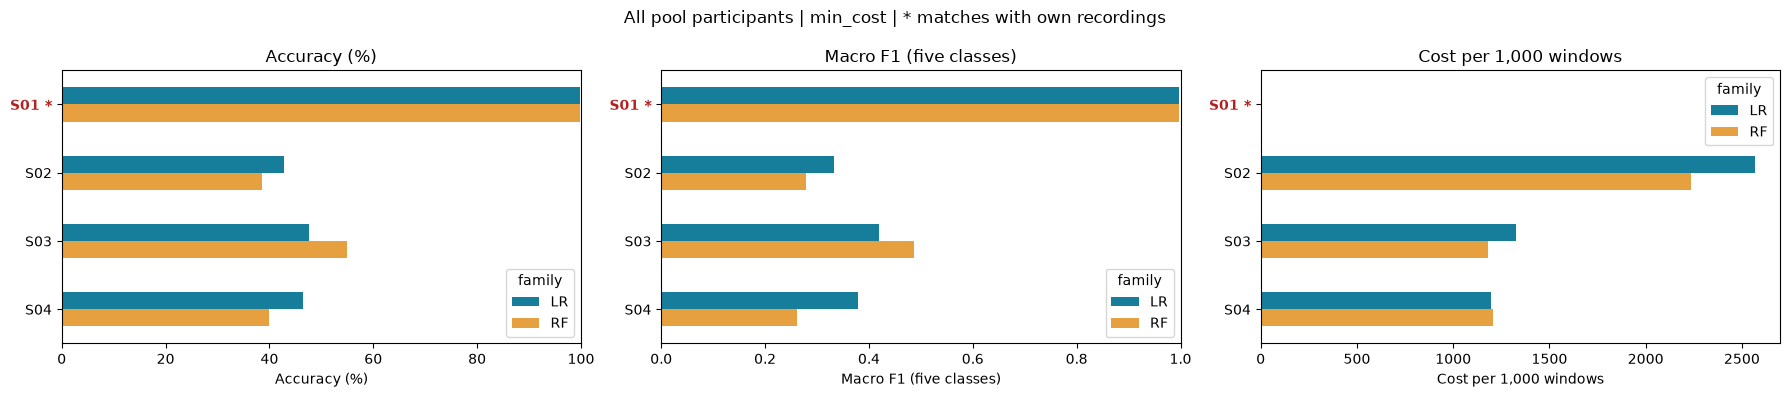

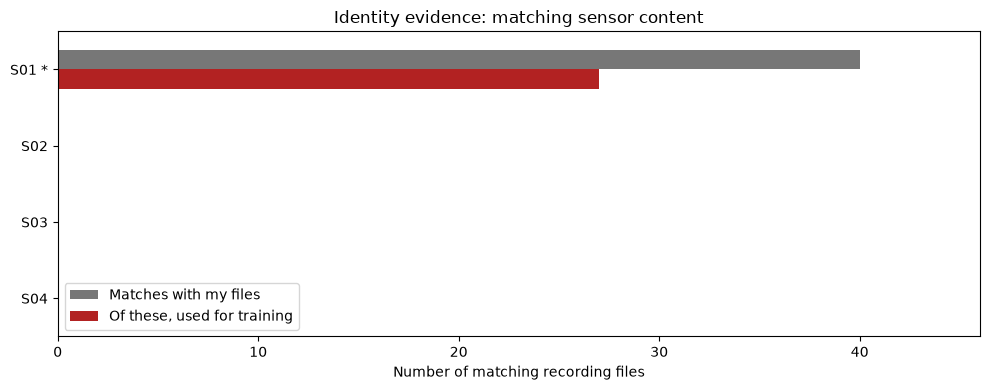

,Matches with my files,"Of these, used for training"
person,,
S01,40,27
S02,0,0
S03,0,0
S04,0,0


Unique own-data match candidate: S01 - review the evidence before confirming identity.


In [37]:
# Compare the frozen models on all pool participants.
RULE = 'min_cost'  # Change to 'argmax' to view the original rule.

if pool_results.empty:
    raise ValueError(
        'No usable pool results. Check pool_manifest.csv and the cleaning audit.'
    )

results_to_plot = pool_results.loc[
    pool_results.primary & pool_results.rule.eq(RULE)
].copy()

if results_to_plot.empty:
    raise ValueError('No primary results for the selected decision rule.')

# Include recognised participants with no usable results.
manifest = pd.read_csv(ART/'tables/pool_manifest.csv')
people = sorted(
    set(manifest['code'].dropna().astype(str)) - {'me'}
)
evaluated = set(results_to_plot.person.astype(str))

# Count sensor-content matches already found by run_pool().
identity = pd.DataFrame(
    0,
    index=people,
    columns=['Matches with my files', 'Of these, used for training']
)
identity.index.name = 'person'

if not pool_matches.empty:
    identity.iloc[:, 0] = (
        pool_matches.groupby('code')['file']
        .nunique()
        .reindex(people, fill_value=0)
    )

    # Check which matched files actually belonged to final training.
    frozen = json.loads((ART/'frozen_config.json').read_text())
    trained_recordings = set(frozen['development_recordings'])

    training_matches = pool_matches[
        pool_matches.own_file.map(
            lambda name: Path(name).stem
        ).isin(trained_recordings)
    ]

    identity.iloc[:, 1] = (
        training_matches.groupby('code')['file']
        .nunique()
        .reindex(people, fill_value=0)
    )

candidates = identity.index[identity.iloc[:, 0].gt(0)].tolist()

labels = {person: person for person in people}
for person in people:
    if person in candidates:
        labels[person] += ' *'
    if person not in evaluated:
        labels[person] += ' (no usable data)'

# Figure 1: performance of both models for every participant.
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, max(4, 0.45*len(people)))
)

for ax, metric, title, factor in zip(
    axes,
    ['accuracy', 'macro_f1', 'cost_per_1000'],
    ['Accuracy (%)', 'Macro F1 (five classes)', 'Cost per 1,000 windows'],
    [100, 1, 1]
):
    table = results_to_plot.pivot(
        index='person', columns='family', values=metric
    )
    table = (
        table.reindex(index=people, columns=['LR', 'RF']) * factor
    ).rename(index=labels)

    table.plot.barh(ax=ax, color=['#167d9a', '#e7a040'])
    ax.invert_yaxis()
    ax.set(title=title, xlabel=title, ylabel='')
    ax.set_xlim(left=0)

    if metric == 'accuracy':
        ax.set_xlim(0, 100)
    elif metric == 'macro_f1':
        ax.set_xlim(0, 1)

    for tick in ax.get_yticklabels():
        if '*' in tick.get_text():
            tick.set_color('#b22222')
            tick.set_fontweight('bold')

fig.suptitle(
    f'All pool participants | {RULE} | * matches with own recordings'
)
fig.tight_layout()
fig.savefig(
    ART/'figures/05_across_person_comparison.png',
    dpi=160
)
plt.show()

# Figure 2: evidence for identifying your anonymous code.
fig, ax = plt.subplots(
    figsize=(10, max(4, 0.4*len(people)))
)

identity.rename(index=labels).plot.barh(
    ax=ax, color=['#777777', '#b22222']
)
ax.invert_yaxis()
ax.set(
    title='Identity evidence: matching sensor content',
    xlabel='Number of matching recording files',
    ylabel=''
)
ax.set_xlim(0, max(1, identity.to_numpy().max())*1.15)

fig.tight_layout()
fig.savefig(
    ART/'figures/06_pool_identity_matches.png',
    dpi=160
)
plt.show()
display(identity)

if len(candidates) == 1:
    print(
        'Unique own-data match candidate:', candidates[0],
        '- review the evidence before confirming identity.'
    )
elif candidates:
    print(
        'Multiple codes match own files; identity is ambiguous:',
        candidates
    )
else:
    print(
        'No own-file matches found. '
        'Identity cannot be inferred from accuracy.'
    )

if set(people) - evaluated:
    print(
        'No usable results for:',
        sorted(set(people) - evaluated)
    )




### Sources to read and cite

1. Mullery, S. ML Lectures 
2. Mullery, S. (2026). *ML Assignment 1 — Starter notebook*. **Machine Learning · Atlantic Technological University · Dr Seán Mullery**. 
3. Anguita, D., Ghio, A., Oneto, L., Parra, X. and Reyes-Ortiz, J. L. (2013). *A Public Domain Dataset for Human Activity Recognition Using Smartphones*. ESANN, pp. 437–442. [Primary paper](https://www.esann.org/sites/default/files/proceedings/legacy/es2013-84.pdf).
4. Reyes-Ortiz, J. et al. (2012). *Human Activity Recognition Using Smartphones*. UCI Machine Learning Repository. DOI: 10.24432/C54S4K. [Dataset description](https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones).
5. scikit-learn developers. [LogisticRegression](https://scikit-learn.org/1.8/modules/generated/sklearn.linear_model.LogisticRegression.html), [RandomForestClassifier](https://scikit-learn.org/1.8/modules/generated/sklearn.ensemble.RandomForestClassifier.html) and cross-validation documentation, version 1.8.0 used in the verified experiment.
6. Breiman, L. (2001). *Random Forests*. Machine Learning 45, pp. 5–32. DOI: 10.1023/A:1010933404324.
7. Elkan, C. (2001). *The Foundations of Cost-Sensitive Learning*. IJCAI, pp. 973–978. [Primary paper](https://cseweb.ucsd.edu/~elkan/rescale.pdf).


